# LSV 模型

**用于捕捉基金“抱团”羊群效应的行为金融模型**

LSV 模型的核心指标计算如下：

$$
\text{LSV}_{i,t} = \left| p_{i,t} - p_t \right| - \mathbb{E}\left| p_{i,t} - p_t \right|
$$

其中，第二项为在无羊群效应假设下的期望绝对偏差，其计算公式为：

$$
\mathbb{E}\left| p_{i,t} - p_t \right| = \text{AF}(i,t) = \sum_{k=1}^{N_{i,t}} \binom{N_{i,t}}{k} p_t^k (1 - p_t)^{N_{i,t}-k} \left| \frac{k}{N_{i,t}} - p_t \right|
$$

各基础变量定义如下：

$$
p_{i,t} = \frac{B(i,t)}{B(i,t) + S(i,t)}
$$$$
p_t = \frac{\sum_{i=1}^{N} p_{i,t}}{N}
$$$$
N_{i,t} = B(i,t) + S(i,t)
$$

其中：

* $B(i,t)$ 为在区间 $t$ 内买入股票 $i$ 的基金数量（即报告期持仓相较上期增加的基金数）；
* $S(i,t)$ 为在区间 $t$ 内卖出股票 $i$ 的基金数量（即报告期持仓相较上期减少的基金数）；
* $N_{i,t}$ 为持仓发生变动的基金总数（买入基金与卖出基金之和）；
* $p_{i,t}$ 为股票 $i$ 在区间 $t$ 内买入基金的占比；
* $p_t$ 为全市场所有股票在区间 $t$ 内买入基金占比的均值（跨股票平均值）；
* $N$ 为全市场股票总数。

## 计算示例

以基金年报或半年报持仓数据为例，若在报告期内有 300 只基金对股票 $i$ 进行了加仓操作，50 只基金进行了减仓操作，则：

$$
B(i,t) = 300,\quad S(i,t) = 50,\quad N_{i,t} = 350
$$$$
p_{i,t} = \frac{300}{350} \approx 0.857
$$

## 因子说明

LSV 模型从基金持股变动数据出发，通过比较某只股票实际被买入的比例与全市场平均买入比例的偏差程度，来判断该股票是否被基金集中买入或集中卖出，从而有效捕捉基金“抱团”现象。

当 $\text{LSV}_{i,t} > 0$ 且数值较大时，表明股票 $i$ 在当期存在显著的基金集体买入或集体卖出行为，即基金“抱团”现象明显。基金抱团是股票出现羊群效应的潜在驱动因子之一，抱团行为可能导致股价偏离基本面价值，并在未来出现价格反转。

数据：基金持仓数据

In [ ]:
# import sys

# !{sys.executable} -m pip install --user --upgrade --no-cache-dir -i https://pypi.org/simple "rqdatac==3.4.2" "rqdatac-fund==1.0.44"

## 有权限

In [1]:
# import numpy as np
# import pandas as pd
# from math import lgamma

# from rqdatac import fund, get_trading_dates


# def _lsv_adjustment_factor(n_funds, market_buy_ratio):
#     """
#     AF(i,t) = E[|K / N - p_t|]
#     其中 K ~ Binomial(N, p_t)。
#     """
#     if n_funds <= 0:
#         return np.nan

#     if market_buy_ratio <= 0.0 or market_buy_ratio >= 1.0:
#         return 0.0

#     k = np.arange(n_funds + 1, dtype=float)

#     # 以 log-PMF 计算，避免组合数溢出
#     log_combination = np.array([
#         lgamma(n_funds + 1)
#         - lgamma(int(value) + 1)
#         - lgamma(n_funds - int(value) + 1)
#         for value in k
#     ])

#     log_probability = (
#         log_combination
#         + k * np.log(market_buy_ratio)
#         + (n_funds - k) * np.log(1.0 - market_buy_ratio)
#     )

#     probability = np.exp(log_probability)

#     return np.sum(
#         probability
#         * np.abs(k / n_funds - market_buy_ratio)
#     )


# def _lsv_get_fund_ids(
#     fund_ids=None,
#     fund_types=("Stock", "Hybrid"),
#     asof_date=None,
# ):
#     """默认选取股票型与混合型公募基金。"""
#     if fund_ids is not None:
#         if isinstance(fund_ids, str):
#             return [fund_ids]
#         return list(dict.fromkeys(fund_ids))

#     fund_info = fund.all_instruments(date=asof_date)

#     return (
#         fund_info.loc[
#             fund_info["fund_type"].isin(fund_types),
#             "order_book_id",
#         ]
#         .dropna()
#         .drop_duplicates()
#         .tolist()
#     )


# def _lsv_download_holdings(
#     fund_ids,
#     fund_batch_size=100,
# ):
#     """
#     下载全部历史基金持仓。

#     返回字段：
#         fund_id, report_date, order_book_id, shares, release_date
#     """
#     parts = []

#     for start in range(0, len(fund_ids), fund_batch_size):
#         batch = fund_ids[start:start + fund_batch_size]

#         raw = fund.get_holdings(
#             order_book_ids=batch,
#         )

#         if raw is None or raw.empty:
#             continue

#         temp = raw.reset_index()

#         required_columns = {
#             "fund_id",
#             "date",
#             "order_book_id",
#             "shares",
#             "release_date",
#         }

#         missing_columns = required_columns - set(temp.columns)
#         if missing_columns:
#             raise ValueError(
#                 "基金持仓数据缺少字段：{}".format(
#                     sorted(missing_columns)
#                 )
#             )

#         # 只保留 A 股股票持仓
#         if "type" in temp.columns:
#             temp = temp[temp["type"] == "Stock"]

#         if "category" in temp.columns:
#             temp = temp[
#                 temp["category"]
#                 .astype(str)
#                 .str.lower()
#                 .eq("ashare")
#             ]

#         temp["date"] = pd.to_datetime(temp["date"])
#         temp["release_date"] = pd.to_datetime(
#             temp["release_date"]
#         )
#         temp["shares"] = pd.to_numeric(
#             temp["shares"],
#             errors="coerce",
#         )

#         temp = temp.dropna(
#             subset=[
#                 "fund_id",
#                 "date",
#                 "order_book_id",
#                 "shares",
#                 "release_date",
#             ]
#         )

#         parts.append(
#             temp[
#                 [
#                     "fund_id",
#                     "date",
#                     "order_book_id",
#                     "shares",
#                     "release_date",
#                 ]
#             ]
#         )

#     if not parts:
#         raise RuntimeError("未取得有效基金持仓数据。")

#     holdings = pd.concat(parts, ignore_index=True)

#     # 同一基金、报告期、股票如有重复记录，合并持仓股数
#     holdings = (
#         holdings
#         .groupby(
#             ["fund_id", "date", "order_book_id"],
#             as_index=False,
#         )
#         .agg({
#             "shares": "sum",
#             "release_date": "max",
#         })
#     )

#     return holdings.rename(columns={"date": "report_date"})


# def _lsv_report_factors(
#     holdings,
#     report_months=(6, 12),
#     share_tolerance=1e-8,
# ):
#     """
#     基于相邻报告期持仓，生成每个报告期的 LSV 横截面结果。
#     """
#     holdings = holdings[
#         holdings["report_date"].dt.month.isin(report_months)
#     ].copy()

#     report_dates = sorted(
#         holdings["report_date"].drop_duplicates().tolist()
#     )

#     report_factor_parts = []

#     for date_index in range(1, len(report_dates)):
#         previous_date = report_dates[date_index - 1]
#         current_date = report_dates[date_index]

#         previous = holdings[
#             holdings["report_date"] == previous_date
#         ].copy()

#         current = holdings[
#             holdings["report_date"] == current_date
#         ].copy()

#         # 仅使用两个报告期均有披露持仓的基金，
#         # 避免把“未披露”错误视作“清仓”。
#         common_funds = np.intersect1d(
#             previous["fund_id"].unique(),
#             current["fund_id"].unique(),
#         )

#         if len(common_funds) == 0:
#             continue

#         previous = previous[
#             previous["fund_id"].isin(common_funds)
#         ]
#         current = current[
#             current["fund_id"].isin(common_funds)
#         ]

#         merged = pd.merge(
#             current[
#                 ["fund_id", "order_book_id", "shares"]
#             ].rename(columns={"shares": "shares_current"}),
#             previous[
#                 ["fund_id", "order_book_id", "shares"]
#             ].rename(columns={"shares": "shares_previous"}),
#             on=["fund_id", "order_book_id"],
#             how="outer",
#         )

#         merged["shares_current"] = (
#             merged["shares_current"].fillna(0.0)
#         )
#         merged["shares_previous"] = (
#             merged["shares_previous"].fillna(0.0)
#         )

#         change = (
#             merged["shares_current"]
#             - merged["shares_previous"]
#         )

#         buy_count = (
#             merged.loc[
#                 change > share_tolerance
#             ]
#             .groupby("order_book_id")["fund_id"]
#             .nunique()
#             .rename("B")
#         )

#         sell_count = (
#             merged.loc[
#                 change < -share_tolerance
#             ]
#             .groupby("order_book_id")["fund_id"]
#             .nunique()
#             .rename("S")
#         )

#         stock_changes = pd.concat(
#             [buy_count, sell_count],
#             axis=1,
#         ).fillna(0.0)

#         stock_changes["N"] = (
#             stock_changes["B"] + stock_changes["S"]
#         )
#         stock_changes = stock_changes[
#             stock_changes["N"] > 0
#         ].copy()

#         if stock_changes.empty:
#             continue

#         stock_changes["p_i"] = (
#             stock_changes["B"] / stock_changes["N"]
#         )

#         # p_t 只对实际发生买卖变化的股票求横截面均值
#         market_buy_ratio = stock_changes["p_i"].mean()

#         stock_changes["p_t"] = market_buy_ratio

#         af_map = {
#             n_funds: _lsv_adjustment_factor(
#                 int(n_funds),
#                 market_buy_ratio,
#             )
#             for n_funds in stock_changes["N"].unique()
#         }

#         stock_changes["AF"] = stock_changes["N"].map(af_map)

#         stock_changes["LSV"] = (
#             (stock_changes["p_i"] - market_buy_ratio).abs()
#             - stock_changes["AF"]
#         )

#         # 因子在该报告期最后一份有效持仓披露后才可使用
#         available_date = current["release_date"].max()

#         stock_changes = stock_changes.reset_index()
#         stock_changes["report_date"] = current_date
#         stock_changes["available_date"] = available_date

#         report_factor_parts.append(stock_changes)

#     if not report_factor_parts:
#         raise RuntimeError("没有足够的相邻基金报告期用于计算 LSV。")

#     return pd.concat(report_factor_parts, ignore_index=True)


# def calculate_lsv_daily(
#     start_date,
#     end_date,
#     candidate_ids=None,
#     fund_ids=None,
#     fund_types=("Stock", "Hybrid"),
#     report_months=(6, 12),
#     fund_batch_size=100,
#     share_tolerance=1e-8,
# ):
#     """
#     基金抱团羊群效应因子（LSV）

#     输出：
#         index  : [date, order_book_id]
#         column : LSV

#     默认：
#         - 使用股票型、混合型基金；
#         - 使用半年报、年报，即 report_months=(6, 12)；
#         - 使用实际 release_date 的下一交易日作为因子生效日。
#     """
#     start_date = pd.Timestamp(start_date)
#     end_date = pd.Timestamp(end_date)

#     fund_ids = _lsv_get_fund_ids(
#         fund_ids=fund_ids,
#         fund_types=fund_types,
#         asof_date=end_date,
#     )

#     holdings = _lsv_download_holdings(
#         fund_ids=fund_ids,
#         fund_batch_size=fund_batch_size,
#     )

#     report_factor = _lsv_report_factors(
#         holdings=holdings,
#         report_months=report_months,
#         share_tolerance=share_tolerance,
#     )

#     # 使用披露日的下一交易日，避免使用同日盘后才公开的信息
#     release_dates = pd.DatetimeIndex(
#         report_factor["available_date"].dropna().unique()
#     )

#     signal_calendar = pd.DatetimeIndex(
#         get_trading_dates(
#             start_date=release_dates.min(),
#             end_date=end_date,
#         )
#     )

#     def next_trading_date(date):
#         position = signal_calendar.searchsorted(
#             pd.Timestamp(date),
#             side="right",
#         )

#         if position >= len(signal_calendar):
#             return pd.NaT

#         return signal_calendar[position]

#     report_factor["signal_date"] = report_factor[
#         "available_date"
#     ].map(next_trading_date)

#     report_factor = report_factor.dropna(
#         subset=["signal_date"]
#     )

#     if candidate_ids is None:
#         candidate_ids = (
#             report_factor["order_book_id"]
#             .dropna()
#             .drop_duplicates()
#             .tolist()
#         )
#     elif isinstance(candidate_ids, str):
#         candidate_ids = [candidate_ids]
#     else:
#         candidate_ids = list(dict.fromkeys(candidate_ids))

#     report_factor = report_factor[
#         report_factor["order_book_id"].isin(candidate_ids)
#     ].copy()

#     # 同一天如有多个报告期快照，保留最新报告期
#     report_factor = (
#         report_factor
#         .sort_values(["signal_date", "report_date"])
#         .drop_duplicates(
#             subset=["signal_date", "order_book_id"],
#             keep="last",
#         )
#     )

#     snapshot_wide = report_factor.pivot(
#         index="signal_date",
#         columns="order_book_id",
#         values="LSV",
#     )

#     target_dates = pd.DatetimeIndex(
#         get_trading_dates(
#             start_date=start_date,
#             end_date=end_date,
#         )
#     )

#     all_dates = target_dates.union(
#         snapshot_wide.index
#     ).sort_values()

#     # 非日频基金持仓因子：披露后前向填充为日频信号
#     daily_wide = (
#         snapshot_wide
#         .reindex(index=all_dates, columns=candidate_ids)
#         .ffill()
#         .reindex(target_dates)
#     )

#     result = daily_wide.stack(dropna=True).rename("LSV").to_frame()
#     result.index = result.index.set_names(
#         ["date", "order_book_id"]
#     )

#     return result

In [ ]:
# import rqdatac
# from rqdatac import fund

# print("rqdatac:", rqdatac.__version__)
# print("基金模块可用：", fund is not None)
# fund.all_instruments().head()

In [ ]:
# lsv = calculate_lsv_daily(
#     start_date="2020-01-01",
#     end_date="2025-12-31",
#     candidate_ids=None,
#     fund_types=("Stock", "Hybrid"),
#     report_months=(6, 12),
#     fund_batch_size=100,
# )

# lsv.head()

# # 若要使用季报持仓，将 report_months 改为：
# # report_months=(3, 6, 9, 12)

## 无权限，使用本地数据

### OLD：不对参与基金数量做限制

In [ ]:
# %pip install --user --only-binary=:all: --timeout 300 --retries 5 "pyarrow==16.1.0" -i https://pypi.tuna.tsinghua.edu.cn/simple

In [7]:
# import zipfile
# from pathlib import Path
# from math import lgamma

# import numpy as np
# import pandas as pd


# def _lsv_adjustment_factor(n_funds, market_buy_ratio):
#     """
#     AF(i,t) = E[|K / N - p_t|], K ~ Binomial(N, p_t)
#     """
#     if n_funds <= 0:
#         return np.nan

#     if market_buy_ratio <= 0.0 or market_buy_ratio >= 1.0:
#         return 0.0

#     k = np.arange(n_funds + 1, dtype=float)

#     log_combination = np.array([
#         lgamma(n_funds + 1)
#         - lgamma(int(value) + 1)
#         - lgamma(n_funds - int(value) + 1)
#         for value in k
#     ])

#     log_probability = (
#         log_combination
#         + k * np.log(market_buy_ratio)
#         + (n_funds - k) * np.log(1.0 - market_buy_ratio)
#     )

#     probability = np.exp(log_probability)

#     return np.sum(
#         probability * np.abs(k / n_funds - market_buy_ratio)
#     )


# def _prepare_local_data(data_zip_path="data.zip", extract_dir="data"):
#     """
#     若尚未解压，则将同目录 data.zip 解压至 data/。
#     """
#     data_zip_path = Path(data_zip_path)
#     extract_dir = Path(extract_dir)

#     if not extract_dir.exists():
#         if not data_zip_path.exists():
#             raise FileNotFoundError(
#                 "未找到 data.zip，请确认其与 Notebook 位于同一目录。"
#             )

#         with zipfile.ZipFile(data_zip_path, "r") as zip_file:
#             zip_file.extractall(".")

#     holdings_dir = extract_dir / "fund_holdings"
#     indicators_dir = extract_dir / "get_comp_indicators"

#     if not holdings_dir.exists():
#         raise FileNotFoundError(
#             "未找到 data/fund_holdings 目录。"
#         )

#     if not indicators_dir.exists():
#         raise FileNotFoundError(
#             "未找到 data/get_comp_indicators 目录。"
#         )

#     return holdings_dir, indicators_dir


# def _load_local_holdings(holdings_dir, report_months=(6, 12)):
#     """
#     读取本地基金持仓，并仅保留 A 股股票持仓。

#     数据字段要求：
#     fund_id, report_date, release_date,
#     order_book_id, shares, type, category
#     """
#     files = sorted(Path(holdings_dir).glob("*.parquet"))

#     if not files:
#         raise RuntimeError("fund_holdings 目录中没有 parquet 文件。")

#     required_columns = {
#         "fund_id",
#         "report_date",
#         "release_date",
#         "order_book_id",
#         "shares",
#         "type",
#         "category",
#     }

#     parts = []

#     for file_path in files:
#         temp = pd.read_parquet(file_path)

#         missing_columns = required_columns - set(temp.columns)
#         if missing_columns:
#             raise ValueError(
#                 "{} 缺少字段：{}".format(
#                     file_path.name,
#                     sorted(missing_columns),
#                 )
#             )

#         temp["report_date"] = pd.to_datetime(
#             temp["report_date"]
#         )
#         temp["release_date"] = pd.to_datetime(
#             temp["release_date"]
#         )
#         temp["shares"] = pd.to_numeric(
#             temp["shares"],
#             errors="coerce",
#         )

#         temp = temp[
#             temp["report_date"].dt.month.isin(report_months)
#         ]

#         # 保留 A 股股票持仓
#         temp = temp[
#             temp["type"].eq("Stock")
#             & temp["category"].astype(str).str.lower().eq("ashare")
#         ]

#         temp = temp.dropna(
#             subset=[
#                 "fund_id",
#                 "report_date",
#                 "release_date",
#                 "order_book_id",
#                 "shares",
#             ]
#         )

#         parts.append(
#             temp[
#                 [
#                     "fund_id",
#                     "report_date",
#                     "release_date",
#                     "order_book_id",
#                     "shares",
#                 ]
#             ]
#         )

#     holdings = pd.concat(parts, ignore_index=True)

#     # 同基金、同报告期、同股票若有多条记录，则汇总持股数
#     holdings = (
#         holdings
#         .groupby(
#             ["fund_id", "report_date", "order_book_id"],
#             as_index=False,
#         )
#         .agg(
#             shares=("shares", "sum"),
#             release_date=("release_date", "max"),
#         )
#     )

#     return holdings


# def _load_local_trading_dates(indicators_dir):
#     """
#     从 get_comp_indicators 的文件名中提取交易日。

#     文件结构示例：
#     data/get_comp_indicators/xxx/2025-01-02.parquet
#     """
#     trading_dates = []

#     for file_path in Path(indicators_dir).rglob("*.parquet"):
#         try:
#             trading_dates.append(pd.Timestamp(file_path.stem))
#         except ValueError:
#             continue

#     trading_dates = pd.DatetimeIndex(
#         sorted(set(trading_dates))
#     )

#     if trading_dates.empty:
#         raise RuntimeError(
#             "无法从 get_comp_indicators 中提取交易日。"
#         )

#     return trading_dates


# def _build_lsv_report_factor(
#     holdings,
#     share_tolerance=1e-8,
# ):
#     """
#     基于相邻报告期持仓构造报告期 LSV 横截面。
#     """
#     report_dates = sorted(
#         holdings["report_date"].drop_duplicates().tolist()
#     )

#     factor_parts = []

#     for previous_date, current_date in zip(
#         report_dates[:-1],
#         report_dates[1:],
#     ):
#         previous = holdings[
#             holdings["report_date"] == previous_date
#         ].copy()

#         current = holdings[
#             holdings["report_date"] == current_date
#         ].copy()

#         # 仅使用两个报告期均有披露记录的基金
#         common_funds = np.intersect1d(
#             previous["fund_id"].unique(),
#             current["fund_id"].unique(),
#         )

#         if len(common_funds) == 0:
#             continue

#         previous = previous[
#             previous["fund_id"].isin(common_funds)
#         ]
#         current = current[
#             current["fund_id"].isin(common_funds)
#         ]

#         merged = pd.merge(
#             current[
#                 ["fund_id", "order_book_id", "shares"]
#             ].rename(columns={"shares": "shares_current"}),
#             previous[
#                 ["fund_id", "order_book_id", "shares"]
#             ].rename(columns={"shares": "shares_previous"}),
#             on=["fund_id", "order_book_id"],
#             how="outer",
#         )

#         merged["shares_current"] = (
#             merged["shares_current"].fillna(0.0)
#         )
#         merged["shares_previous"] = (
#             merged["shares_previous"].fillna(0.0)
#         )

#         holding_change = (
#             merged["shares_current"]
#             - merged["shares_previous"]
#         )

#         buy_count = (
#             merged.loc[
#                 holding_change > share_tolerance
#             ]
#             .groupby("order_book_id")["fund_id"]
#             .nunique()
#             .rename("B")
#         )

#         sell_count = (
#             merged.loc[
#                 holding_change < -share_tolerance
#             ]
#             .groupby("order_book_id")["fund_id"]
#             .nunique()
#             .rename("S")
#         )

#         stock_changes = pd.concat(
#             [buy_count, sell_count],
#             axis=1,
#         ).fillna(0.0)

#         stock_changes["N"] = (
#             stock_changes["B"] + stock_changes["S"]
#         )

#         stock_changes = stock_changes[
#             stock_changes["N"] > 0
#         ].copy()

#         if stock_changes.empty:
#             continue

#         stock_changes["p_i"] = (
#             stock_changes["B"] / stock_changes["N"]
#         )

#         # 按股票横截面等权平均
#         # 第一，市场买入比例 \(p_t\) 不能对股票的 \(p_i\) 做等权平均。应按发生交易的基金—股票记录加权
#         # ❌ market_buy_ratio = stock_changes["p_i"].mean()
#         # LSV 标准定义：按基金—股票交易记录加权
#         market_buy_ratio = (
#             stock_changes["B"].sum()
#             / stock_changes["N"].sum()
#         )
#         stock_changes["p_t"] = market_buy_ratio

#         af_map = {
#             n_funds: _lsv_adjustment_factor(
#                 int(n_funds),
#                 market_buy_ratio,
#             )
#             for n_funds in stock_changes["N"].unique()
#         }

#         stock_changes["AF"] = stock_changes["N"].map(af_map)

#         stock_changes["LSV"] = (
#             (stock_changes["p_i"] - market_buy_ratio).abs()
#             - stock_changes["AF"]
#         )

#         stock_changes = (
#             stock_changes
#             .reset_index()
#             .rename(columns={"index": "order_book_id"})
#         )

#         stock_changes["report_date"] = current_date

#         # 全部基金都已披露后，快照才可以使用
#         stock_changes["available_date"] = (
#             current["release_date"].max()
#         )

#         factor_parts.append(stock_changes)

#     if not factor_parts:
#         raise RuntimeError(
#             "没有足够的相邻报告期用于计算 LSV。"
#         )

#     return pd.concat(factor_parts, ignore_index=True)


# def calculate_lsv_daily_from_local(
#     start_date,
#     end_date,
#     candidate_ids=None,
#     data_zip_path="data.zip",
#     extract_dir="data",
#     report_months=(6, 12),
#     share_tolerance=1e-8,
# ):
#     """
#     使用本地压缩包构建日频 LSV 因子。

#     Parameters
#     ----------
#     start_date, end_date : str
#         因子输出的起止日期。
#     candidate_ids : list[str] or str, optional
#         指定股票池；默认为全部发生基金持仓变化的 A 股。
#     report_months : tuple
#         默认使用中报和年报：(6, 12)。
#         若需要季频持仓比较，使用：(3, 6, 9, 12)。

#     Returns
#     -------
#     pd.DataFrame
#         MultiIndex: [date, order_book_id]
#         Column: LSV
#     """
#     start_date = pd.Timestamp(start_date)
#     end_date = pd.Timestamp(end_date)

#     holdings_dir, indicators_dir = _prepare_local_data(
#         data_zip_path=data_zip_path,
#         extract_dir=extract_dir,
#     )

#     holdings = _load_local_holdings(
#         holdings_dir=holdings_dir,
#         report_months=report_months,
#     )

#     report_factor = _build_lsv_report_factor(
#         holdings=holdings,
#         share_tolerance=share_tolerance,
#     )

#     trading_dates = _load_local_trading_dates(
#         indicators_dir=indicators_dir,
#     )

#     def next_trading_date(date):
#         position = trading_dates.searchsorted(
#             pd.Timestamp(date),
#             side="right",
#         )

#         if position >= len(trading_dates):
#             return pd.NaT

#         return trading_dates[position]

#     report_factor["signal_date"] = report_factor[
#         "available_date"
#     ].map(next_trading_date)

#     report_factor = report_factor.dropna(
#         subset=["signal_date"]
#     )

#     if candidate_ids is None:
#         candidate_ids = (
#             report_factor["order_book_id"]
#             .drop_duplicates()
#             .sort_values()
#             .tolist()
#         )
#     elif isinstance(candidate_ids, str):
#         candidate_ids = [candidate_ids]
#     else:
#         candidate_ids = list(dict.fromkeys(candidate_ids))

#     report_factor = report_factor[
#         report_factor["order_book_id"].isin(candidate_ids)
#     ].copy()

#     # 若同一交易日有多个快照，保留最新报告期
#     report_factor = (
#         report_factor
#         .sort_values(["signal_date", "report_date"])
#         .drop_duplicates(
#             subset=["signal_date", "order_book_id"],
#             keep="last",
#         )
#     )

#     snapshot_wide = report_factor.pivot(
#         index="signal_date",
#         columns="order_book_id",
#         values="LSV",
#     )

#     # 计算开始日前的历史快照也需保留，以便正确前向填充
#     all_dates = trading_dates[
#         (trading_dates >= snapshot_wide.index.min())
#         & (trading_dates <= end_date)
#     ]

#     # 当前日频映射的 .ffill() 会把“本报告期已不再有基金买卖记录”的股票保留为上一期 LSV，这是错误的陈旧因子值。每次新报告快照出现时，未出现在该快照中的股票应变为缺失，而不是沿用旧值。
#     # daily_wide = (
#     #     snapshot_wide
#     #     .reindex(index=all_dates, columns=candidate_ids)
#     #     .ffill()
#     # )

#     daily_wide = pd.DataFrame(
#         np.nan,
#         index=all_dates,
#         columns=candidate_ids,
#         dtype=float,
#     )

#     snapshot_dates = snapshot_wide.index.sort_values()

#     for pos, signal_date in enumerate(snapshot_dates):
#         next_signal_date = (
#             snapshot_dates[pos + 1]
#             if pos + 1 < len(snapshot_dates)
#             else pd.Timestamp.max
#         )

#         effective_dates = all_dates[
#             (all_dates >= signal_date)
#             & (all_dates < next_signal_date)
#         ]

#         # 新报告期中不存在 LSV 的股票会被明确设为 NaN，
#         # 不会错误继承上一报告期的旧值。
#         daily_wide.loc[
#             effective_dates,
#             snapshot_wide.columns,
#         ] = snapshot_wide.loc[signal_date].values
    
#     daily_wide = daily_wide.loc[
#         (daily_wide.index >= start_date)
#         & (daily_wide.index <= end_date)
#     ]

#     result = (
#         daily_wide
#         .stack(dropna=True)
#         .rename("LSV")
#         .to_frame()
#     )

#     result.index = result.index.set_names(
#         ["date", "order_book_id"]
#     )

#     return result, report_factor

In [8]:
# # 示例：构建全部股票的日频 LSV 因子
# lsv, lsv_report = calculate_lsv_daily_from_local(
#     start_date="2020-01-01",
#     end_date="2025-12-31",
#     data_zip_path="data.zip",
#     extract_dir="data",
#     report_months=(6, 12),
# )

# lsv.head()

LSV
date       order_book_id          
2020-01-02 000001.XSHE    0.116963
           000002.XSHE    0.154940
           000004.XSHE    0.023688
           000005.XSHE    0.090992
           000006.XSHE    0.172755

In [9]:
# factor_data = (
#     lsv["LSV"]
#     .unstack("order_book_id")
#     .sort_index()
# )

# factor_data.index = pd.to_datetime(factor_data.index)
# factor_data.columns.name = "order_book_id"
# factor_data

order_book_id,000001.XSHE,000002.XSHE,000004.XSHE,000005.XSHE,000006.XSHE,000007.XSHE,000008.XSHE,000009.XSHE,000011.XSHE,000012.XSHE,...,688757.XSHG,688758.XSHG,688775.XSHG,920019,920029,920037,920068,920108,920786,920906
date,,,,,,,,,,,,,,,,,,,,,
2020-01-02,0.116963,0.154940,0.023688,0.090992,0.172755,-0.021634,0.203355,-0.015225,0.315012,0.123355,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2020-01-03,0.116963,0.154940,0.023688,0.090992,0.172755,-0.021634,0.203355,-0.015225,0.315012,0.123355,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2020-01-06,0.116963,0.154940,0.023688,0.090992,0.172755,-0.021634,0.203355,-0.015225,0.315012,0.123355,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2020-01-07,0.116963,0.154940,0.023688,0.090992,0.172755,-0.021634,0.203355,-0.015225,0.315012,0.123355,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2020-01-08,0.116963,0.154940,0.023688,0.090992,0.172755,-0.021634,0.203355,-0.015225,0.315012,0.123355,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2025-12-25,0.011176,0.190889,NaN,NaN,0.312884,0.302616,0.363728,0.124188,0.256144,-0.019744,...,0.492308,0.491438,0.492634,0.344172,0.402425,0.448393,0.000614,0.420025,0.312884,0.250307
2025-12-26,0.011176,0.190889,NaN,NaN,0.312884,0.302616,0.363728,0.124188,0.256144,-0.019744,...,0.492308,0.491438,0.492634,0.344172,0.402425,0.448393,0.000614,0.420025,0.312884,0.250307
2025-12-29,0.011176,0.190889,NaN,NaN,0.312884,0.302616,0.363728,0.124188,0.256144,-0.019744,...,0.492308,0.491438,0.492634,0.344172,0.402425,0.448393,0.000614,0.420025,0.312884,0.250307


In [10]:
# factor_data.to_csv("lsv.csv", index=True)

🚨 fund_holdings 必须是基金完整持仓，而不能只是“前十大重仓股”。若仅包含前十大，某股票从文件中消失不等于基金卖出，LSV 的买卖判断将不成立。

In [12]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

def check_lsv_output(
    lsv_panel,
    lsv_report,
    start_date="2020-01-01",
    end_date="2025-12-31",
    trading_dates=None,
    factor_name="LSV",
):
    """检查日频 LSV 因子和报告期 LSV 中间结果。"""

    required_report_columns = {
        "order_book_id",
        "report_date",
        "available_date",
        "signal_date",
        "B",
        "S",
        "N",
        "p_i",
        "p_t",
        "AF",
        "LSV",
    }

    missing_columns = required_report_columns - set(
        lsv_report.columns
    )

    if missing_columns:
        raise ValueError(
            "lsv_report 缺少字段：{}".format(
                sorted(missing_columns)
            )
        )

    report = lsv_report.copy()

    for column in [
        "report_date",
        "available_date",
        "signal_date",
    ]:
        report[column] = pd.to_datetime(report[column])

    report = report[
        (report["signal_date"] >= pd.Timestamp(start_date))
        & (report["signal_date"] <= pd.Timestamp(end_date))
    ].copy()

    # 与主计算逻辑一致：同一信号日、同一股票仅保留最新报告期。
    report = (
        report
        .sort_values(["signal_date", "report_date"])
        .drop_duplicates(
            subset=["signal_date", "order_book_id"],
            keep="last",
        )
    )

    # 标准定义下的加权市场买入比例。
    weighted_p_t = report.groupby("report_date").apply(
        lambda x: x["B"].sum() / x["N"].sum()
    )

    report["weighted_p_t"] = report["report_date"].map(
        weighted_p_t
    )

    report["p_t_error"] = (
        report["p_t"] - report["weighted_p_t"]
    ).abs()

    n_mismatch = (
        report["N"] - report["B"] - report["S"]
    ).abs()

    lower_bound = -report["AF"]
    upper_bound = (
        np.maximum(
            report["p_t"],
            1.0 - report["p_t"],
        )
        - report["AF"]
    )

    lsv_lower_violation = (
        report["LSV"] < lower_bound - 1e-12
    ).sum()

    lsv_upper_violation = (
        report["LSV"] > upper_bound + 1e-12
    ).sum()

    # 日频因子面板。
    if not isinstance(lsv_panel.index, pd.MultiIndex):
        raise ValueError(
            "lsv_panel 必须使用 (date, order_book_id) 两层索引。"
        )

    data = lsv_panel[[factor_name]].copy()
    data.index = data.index.set_names(
        ["date", "order_book_id"]
    )
    data = data.reset_index()

    data["date"] = pd.to_datetime(data["date"])
    data = data[
        (data["date"] >= pd.Timestamp(start_date))
        & (data["date"] <= pd.Timestamp(end_date))
    ].copy()

    data["_value"] = pd.to_numeric(
        data[factor_name],
        errors="coerce",
    )

    duplicate_count = data.duplicated(
        ["date", "order_book_id"]
    ).sum()

    missing_count = data["_value"].isna().sum()

    inf_count = (
        data["_value"].notna()
        & (~np.isfinite(data["_value"]))
    ).sum()

    valid = data[
        data["_value"].notna()
        & np.isfinite(data["_value"])
    ].copy()

    values = valid["_value"]

    daily = valid.groupby("date")["_value"].agg(
        ["count", "mean", "std", "min", "median", "max"]
    )

    daily["P01"] = valid.groupby("date")["_value"].quantile(0.01)
    daily["P05"] = valid.groupby("date")["_value"].quantile(0.05)
    daily["P95"] = valid.groupby("date")["_value"].quantile(0.95)
    daily["P99"] = valid.groupby("date")["_value"].quantile(0.99)

    daily = daily.rename(columns={
        "count": "因子股票数",
        "mean": "均值",
        "std": "标准差",
        "min": "最小值",
        "median": "中位数",
        "max": "最大值",
    })

    stock_days = valid.groupby("order_book_id").size()

    # 每个新信号日，日频因子应与报告期快照完全一致；
    # 不应遗留上一个报告期、但本期未出现的股票。
    signal_dates = pd.DatetimeIndex(
        sorted(report["signal_date"].drop_duplicates())
    )

    stale_count = 0
    missing_snapshot_count = 0

    for signal_date in signal_dates:
        expected_ids = set(
            report.loc[
                report["signal_date"] == signal_date,
                "order_book_id",
            ]
        )

        actual_ids = set(
            valid.loc[
                valid["date"] == signal_date,
                "order_book_id",
            ]
        )

        stale_count += len(actual_ids - expected_ids)
        missing_snapshot_count += len(expected_ids - actual_ids)

    expected_values = report[
        ["signal_date", "order_book_id", "LSV"]
    ].rename(columns={
        "signal_date": "date",
        "LSV": "report_lsv",
    })

    actual_values = valid[
        valid["date"].isin(signal_dates)
    ][
        ["date", "order_book_id", "_value"]
    ].rename(columns={
        "_value": "daily_lsv",
    })

    compare_values = expected_values.merge(
        actual_values,
        on=["date", "order_book_id"],
        how="inner",
    )

    snapshot_value_error = (
        compare_values["report_lsv"]
        - compare_values["daily_lsv"]
    ).abs()

    # LSV 应只在 signal_date 发生变化。
    if trading_dates is not None:
        calendar = pd.DatetimeIndex(
            pd.to_datetime(trading_dates)
        )
        calendar = calendar[
            (calendar >= pd.Timestamp(start_date))
            & (calendar <= pd.Timestamp(end_date))
        ]
    else:
        calendar = pd.DatetimeIndex(
            sorted(valid["date"].unique())
        )

    position_map = pd.Series(
        np.arange(len(calendar)),
        index=calendar,
    )

    ordered = valid.sort_values(
        ["order_book_id", "date"]
    ).copy()

    ordered["_previous_value"] = ordered.groupby(
        "order_book_id"
    )["_value"].shift(1)

    ordered["_previous_date"] = ordered.groupby(
        "order_book_id"
    )["date"].shift(1)

    ordered["_position"] = ordered["date"].map(position_map)
    ordered["_previous_position"] = ordered.groupby(
        "order_book_id"
    )["_position"].shift(1)

    ordered["_continuous"] = (
        ordered["_position"] - ordered["_previous_position"]
    ).eq(1)

    ordered["_changed"] = (
        ordered["_value"] - ordered["_previous_value"]
    ).abs().gt(1e-12) & ordered["_continuous"]

    changed_outside_signal = ordered[
        ordered["_changed"]
        & (~ordered["date"].isin(signal_dates))
    ].shape[0]

    report_by_period = report.groupby("report_date").agg(
        股票数=("order_book_id", "nunique"),
        平均参与基金数=("N", "mean"),
        P05参与基金数=("N", lambda x: x.quantile(0.05)),
        最大参与基金数=("N", "max"),
        市场买入比例=("p_t", "first"),
        加权市场买入比例=("weighted_p_t", "first"),
        LSV均值=("LSV", "mean"),
        LSV标准差=("LSV", "std"),
        LSV最小值=("LSV", "min"),
        LSV中位数=("LSV", "median"),
        LSV最大值=("LSV", "max"),
    )

    summary = pd.DataFrame([
        ["报告期快照数",
         report["report_date"].nunique(),
         "半年报数据通常约每年 2 次"],
        ["可用信号日数",
         report["signal_date"].nunique(),
         "每个报告期通常对应一个可用信号日"],
        ["报告期股票观测数", len(report), ""],
        ["报告期覆盖股票数",
         report["order_book_id"].nunique(), ""],
        ["B、S、N 不满足 N=B+S 的记录数",
         int((n_mismatch > 1e-12).sum()),
         "应为 0"],
        ["p_i 超出 [0, 1] 的记录数",
         int(((report["p_i"] < 0) | (report["p_i"] > 1)).sum()),
         "应为 0"],
        ["p_t 超出 [0, 1] 的记录数",
         int(((report["p_t"] < 0) | (report["p_t"] > 1)).sum()),
         "应为 0"],
        ["AF 为负或大于 1 的记录数",
         int(((report["AF"] < 0) | (report["AF"] > 1)).sum()),
         "应为 0"],
        ["LSV 理论下界违规数",
         int(lsv_lower_violation),
         "应为 0"],
        ["LSV 理论上界违规数",
         int(lsv_upper_violation),
         "应为 0"],
        ["p_t 与加权定义最大误差",
         report["p_t_error"].max(),
         "修正后应接近 0"],
        ["日频有效观测数", len(valid), ""],
        ["日频覆盖股票数",
         valid["order_book_id"].nunique(), ""],
        ["重复 date-stock", duplicate_count, "应为 0"],
        ["显式缺失值", missing_count, "最终 stack 后通常应为 0"],
        ["无穷值（inf/-inf）", inf_count, "应为 0"],
        ["日频因子均值", values.mean(), "允许正或负"],
        ["日频因子标准差", values.std(), ""],
        ["负值占比", (values < 0).mean(), "允许存在"],
        ["最小值", values.min(), "理论上应大于等于 -1"],
        ["P01", values.quantile(0.01), ""],
        ["中位数", values.median(), ""],
        ["P99", values.quantile(0.99), ""],
        ["最大值", values.max(), "理论上应小于等于 1"],
        ["单股有效天数 P05",
         stock_days.quantile(0.05),
         "报告期未参与基金交易的股票会较低"],
        ["新快照日残留旧因子值数",
         stale_count,
         "修正日频映射后应为 0"],
        ["新快照日缺少应有因子值数",
         missing_snapshot_count,
         "应为 0"],
        ["快照值与日频值最大误差",
         snapshot_value_error.max(),
         "应接近 0"],
        ["非信号日发生因子变化的记录数",
         changed_outside_signal,
         "应为 0"],
    ], columns=["指标", "数值", "判断"]).set_index("指标")

    print("总体统计：")
    display(summary)

    print("\n各报告期横截面统计：")
    display(report_by_period)

    print("\n最近 5 个有效因子交易日横截面统计：")
    display(daily.tail())

    print("\nLSV 最大的 20 条记录：")
    display(
        valid.sort_values("_value", ascending=False)
        [["date", "order_book_id", factor_name]]
        .head(20)
    )

    print("\nLSV 最小的 20 条记录：")
    display(
        valid.sort_values("_value", ascending=True)
        [["date", "order_book_id", factor_name]]
        .head(20)
    )

    return summary, report_by_period, daily


_, lsv_indicators_dir = _prepare_local_data(
    data_zip_path="data.zip",
    extract_dir="data",
)

lsv_trading_dates = _load_local_trading_dates(
    lsv_indicators_dir
)

lsv_summary, lsv_report_summary, lsv_daily = (
    check_lsv_output(
        lsv_panel=lsv,
        lsv_report=lsv_report,
        start_date="2020-01-01",
        end_date="2025-12-31",
        trading_dates=lsv_trading_dates,
        factor_name="LSV",
    )
)

总体统计：


,数值,判断
指标,,
报告期快照数,1.200000e+01,半年报数据通常约每年 2 次
可用信号日数,1.200000e+01,每个报告期通常对应一个可用信号日
报告期股票观测数,5.333600e+04,
报告期覆盖股票数,5.572000e+03,
B、S、N 不满足 N=B+S 的记录数,0.000000e+00,应为 0
"p_i 超出 [0, 1] 的记录数",0.000000e+00,应为 0
"p_t 超出 [0, 1] 的记录数",0.000000e+00,应为 0
AF 为负或大于 1 的记录数,0.000000e+00,应为 0
LSV 理论下界违规数,0.000000e+00,应为 0



各报告期横截面统计：


,股票数,平均参与基金数,P05参与基金数,最大参与基金数,市场买入比例,加权市场买入比例,LSV均值,LSV标准差,LSV最小值,LSV中位数,LSV最大值
report_date,,,,,,,,,,,
2019-12-31,3450,77.221159,2.0,2657.0,0.524873,0.524873,0.134479,0.160511,-0.236914,0.114681,0.516154
2020-06-30,3452,92.292874,1.0,2851.0,0.522742,0.522742,0.159331,0.162128,-0.238088,0.162107,0.515278
2020-12-31,3535,130.192645,1.0,3249.0,0.596148,0.596148,0.202153,0.180254,-0.190904,0.196524,0.588812
2021-06-30,3737,180.313085,1.0,3831.0,0.544983,0.544983,0.182625,0.173957,-0.225303,0.184731,0.538500
2021-12-31,4189,220.813798,2.0,4375.0,0.532759,0.532759,0.176144,0.173305,-0.232477,0.176727,0.526737
2022-06-30,4429,214.999323,2.0,4765.0,0.415110,0.415110,0.159956,0.167573,-0.199125,0.131095,0.578872
2022-12-31,4768,194.998951,2.0,4687.0,0.496041,0.496041,0.168849,0.162401,-0.248005,0.152510,0.497661
2023-06-30,5006,218.816021,4.0,4175.0,0.535244,0.535244,0.174911,0.152641,-0.163483,0.164911,0.527972
2023-12-31,5129,230.720998,7.0,3280.0,0.502652,0.502652,0.154007,0.145783,-0.248667,0.128993,0.495300



最近 5 个有效因子交易日横截面统计：


,因子股票数,均值,标准差,最小值,中位数,最大值,P01,P05,P95,P99
date,,,,,,,,,,
2025-12-25,5293,0.138818,0.136756,-0.249693,0.118054,0.493483,-0.136272,-0.038266,0.38664,0.482977
2025-12-26,5293,0.138818,0.136756,-0.249693,0.118054,0.493483,-0.136272,-0.038266,0.38664,0.482977
2025-12-29,5293,0.138818,0.136756,-0.249693,0.118054,0.493483,-0.136272,-0.038266,0.38664,0.482977
2025-12-30,5293,0.138818,0.136756,-0.249693,0.118054,0.493483,-0.136272,-0.038266,0.38664,0.482977
2025-12-31,5293,0.138818,0.136756,-0.249693,0.118054,0.493483,-0.136272,-0.038266,0.38664,0.482977



LSV 最大的 20 条记录：


,date,order_book_id,LSV
5223593,2025-02-12,603312.XSHG,0.612855
5044183,2024-12-16,603312.XSHG,0.612855
5064687,2024-12-20,603312.XSHG,0.612855
4736623,2024-09-12,603312.XSHG,0.612855
5336365,2025-03-14,603312.XSHG,0.612855
4854521,2024-10-24,603312.XSHG,0.612855
4772505,2024-09-25,603312.XSHG,0.612855
4905781,2024-11-07,603312.XSHG,0.612855
5013427,2024-12-06,603312.XSHG,0.612855
4818639,2024-10-15,603312.XSHG,0.612855



LSV 最小的 20 条记录：


,date,order_book_id,LSV
6270542,2025-12-05,000410.XSHE,-0.249693
5942376,2025-09-02,000410.XSHE,-0.249693
6058822,2025-10-10,000410.XSHE,-0.249693
6349937,2025-12-26,000410.XSHE,-0.249693
6302300,2025-12-15,000410.XSHE,-0.249693
6217612,2025-11-21,000410.XSHE,-0.249693
6180561,2025-11-12,000410.XSHE,-0.249693
6365816,2025-12-31,000410.XSHE,-0.249693
6138217,2025-10-31,000410.XSHE,-0.249693
6053529,2025-10-09,000410.XSHE,-0.249693


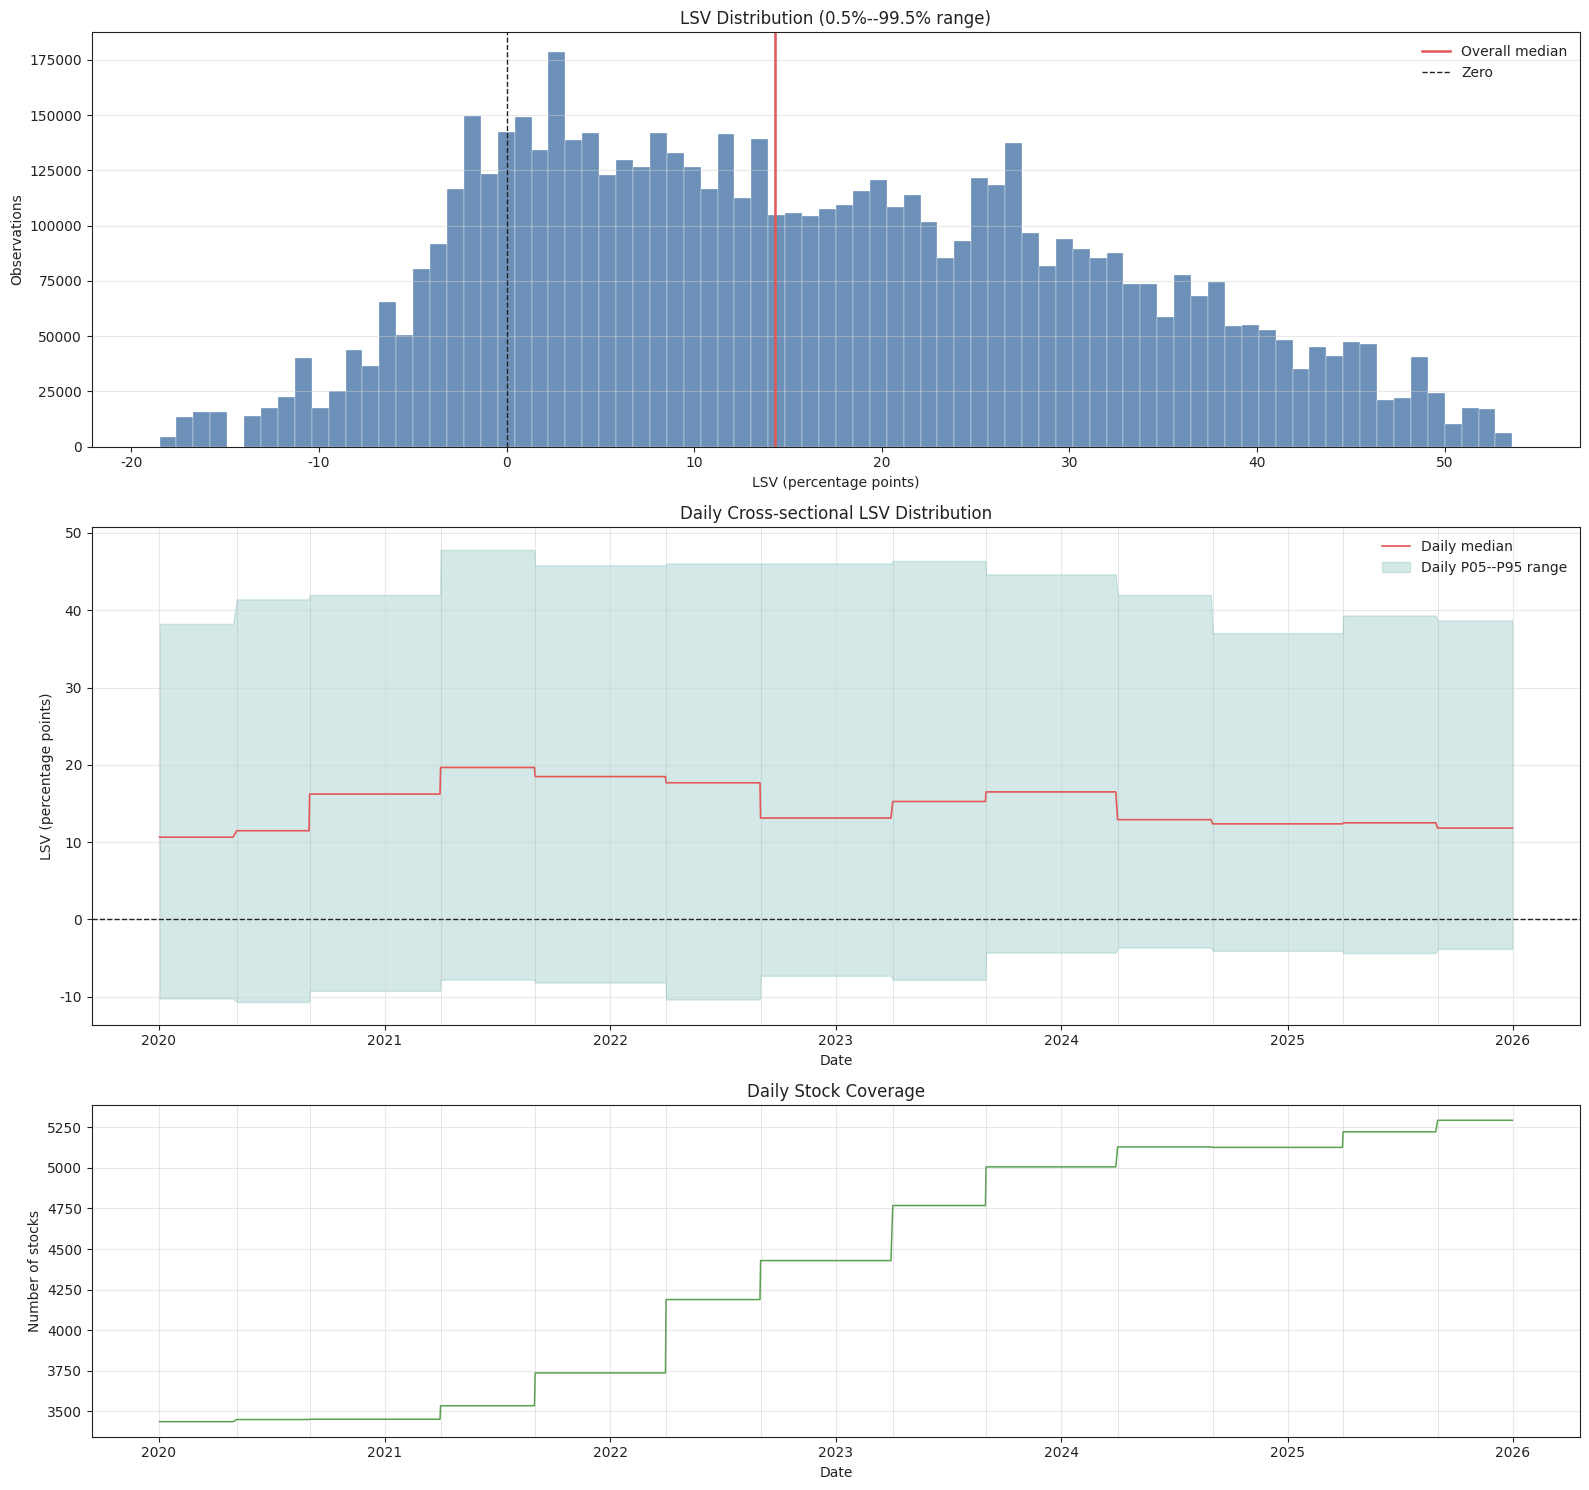

In [14]:
def plot_lsv_distribution(
    lsv_panel,
    lsv_report,
    factor_name="LSV",
    scale=100.0,
):
    """绘制 LSV 分布、横截面变化和有效覆盖。"""

    plt.style.use("default")
    plt.rcParams.update({
        "figure.facecolor": "white",
        "axes.facecolor": "white",
        "savefig.facecolor": "white",
        "axes.edgecolor": "#222222",
        "axes.labelcolor": "#222222",
        "xtick.color": "#222222",
        "ytick.color": "#222222",
        "text.color": "#222222",
        "grid.color": "#D0D0D0",
        "axes.unicode_minus": False,
        "font.family": "DejaVu Sans",
    })

    data = lsv_panel[[factor_name]].copy()
    data.index = data.index.set_names(["date", "order_book_id"])
    data = data.reset_index()

    data["date"] = pd.to_datetime(data["date"])
    data["_value"] = pd.to_numeric(
        data[factor_name],
        errors="coerce",
    )

    data = data[
        data["_value"].notna()
        & np.isfinite(data["_value"])
    ].copy()

    values = data["_value"] * scale

    daily_q = data.groupby("date")["_value"].quantile(
        [0.05, 0.50, 0.95]
    ).unstack() * scale

    daily_q.columns = ["P05", "Median", "P95"]

    daily_count = data.groupby("date").size()

    low = values.quantile(0.005)
    high = values.quantile(0.995)

    histogram_values = values[
        (values >= low) & (values <= high)
    ]

    signal_dates = pd.DatetimeIndex(
        pd.to_datetime(
            lsv_report["signal_date"].drop_duplicates()
        )
    )
    signal_dates = signal_dates[
        (signal_dates >= data["date"].min())
        & (signal_dates <= data["date"].max())
    ]

    fig, axes = plt.subplots(
        3,
        1,
        figsize=(16, 15),
        gridspec_kw={"height_ratios": [1.0, 1.2, 0.8]},
    )

    axes[0].hist(
        histogram_values,
        bins=80,
        color="#4C78A8",
        alpha=0.82,
        edgecolor="white",
        linewidth=0.3,
    )

    axes[0].axvline(
        values.median(),
        color="#E45756",
        linewidth=1.8,
        label="Overall median",
    )

    axes[0].axvline(
        0,
        color="#222222",
        linewidth=1.0,
        linestyle="--",
        label="Zero",
    )

    axes[0].set_title(
        "LSV Distribution (0.5%--99.5% range)"
    )
    axes[0].set_xlabel("LSV (percentage points)")
    axes[0].set_ylabel("Observations")
    axes[0].grid(axis="y", alpha=0.45)
    axes[0].legend(frameon=False)

    axes[1].fill_between(
        daily_q.index,
        daily_q["P05"],
        daily_q["P95"],
        color="#72B7B2",
        alpha=0.30,
        label="Daily P05--P95 range",
    )

    axes[1].plot(
        daily_q.index,
        daily_q["Median"],
        color="#E45756",
        linewidth=1.2,
        label="Daily median",
    )

    axes[1].axhline(
        0,
        color="#222222",
        linewidth=1.0,
        linestyle="--",
    )

    for signal_date in signal_dates:
        axes[1].axvline(
            signal_date,
            color="#999999",
            linewidth=0.5,
            alpha=0.35,
        )

    axes[1].set_title("Daily Cross-sectional LSV Distribution")
    axes[1].set_xlabel("Date")
    axes[1].set_ylabel("LSV (percentage points)")
    axes[1].grid(alpha=0.45)
    axes[1].legend(frameon=False)

    axes[2].plot(
        daily_count.index,
        daily_count.values,
        color="#59A14F",
        linewidth=1.1,
    )

    for signal_date in signal_dates:
        axes[2].axvline(
            signal_date,
            color="#999999",
            linewidth=0.5,
            alpha=0.35,
        )

    axes[2].set_title("Daily Stock Coverage")
    axes[2].set_xlabel("Date")
    axes[2].set_ylabel("Number of stocks")
    axes[2].grid(alpha=0.45)

    for ax in axes:
        for spine in ax.spines.values():
            spine.set_color("#222222")

    plt.tight_layout()
    plt.show()


plot_lsv_distribution(
    lsv_panel=lsv,
    lsv_report=lsv_report,
    factor_name="LSV",
    scale=100.0,
)

结果在计算与映射层面通过，但经济解释上应加入“最少参与基金数”过滤后再作为正式因子使用。

通过项：

- 加权市场买入比例 $p_t$ 正确：最大误差为 0。
- $N=B+S$、$p_i$、$p_t$、AF、LSV 的全部边界检验均通过。
- 日频快照映射正确：无陈旧值、无快照缺失、快照值与日频值完全一致，且非信号日不发生变化。
- 12 个半年报快照覆盖 2020–2025 年，日频因子在两次披露之间保持常数，这是正确行为，不是“日频信息”。

数值上也符合 LSV 的理论范围：

- 均值 `0.1597`，中位数 `0.1431`，P99 `0.5147`，最大值 `0.6129`；
- 最小值 `-0.2497`，没有突破 $[-1,1]$ 的理论范围；
- 正值占比 `83.5%`，说明基金交易方向的集中程度平均显著高于二项分布随机交易下的预期离散度。换言之，样本中存在较强的同向调仓现象。

各报告期的均值在 `0.134—0.202` 之间，2020 年末最高为 `0.202`；市场买入比例则在 `0.380—0.596` 间变化。这种随市场状态变化的横截面 LSV 分布是合理的。

不过，有一个实质性风险：低参与基金数股票会产生“看似极端、实际不稳健”的 LSV。

例如 `000410.XSHE` 的最低值 `-0.249693` 几乎可以判断来自非常小的 $N$。当 $N=2$、一只基金买入一只卖出时：

$$
p_i \approx 0.5,\qquad
AF \approx 0.25,\qquad
LSV \approx -0.25
$$

这并不表示极强的“反羊群”，而只是两只基金方向相反、样本量过小。你的报告期统计也显示早期 P05 的参与基金数仅为 1 或 2，最新报告期 P05 仍只有 6。

因此建议将 LSV 的正式可交易样本限制为至少 10 家参与基金；但市场买入比例 $p_t$ 仍应先用全部股票计算，再过滤低 $N$ 股票：

```python
# 先用全部发生交易的股票计算市场买入比例
market_buy_ratio = (
    stock_changes["B"].sum()
    / stock_changes["N"].sum()
)

# 再过滤低参与基金数股票，只影响输出，不影响 p_t
min_funds_per_stock = 10

stock_changes = stock_changes[
    stock_changes["N"] >= min_funds_per_stock
].copy()

if stock_changes.empty:
    continue

stock_changes["p_i"] = (
    stock_changes["B"] / stock_changes["N"]
)
stock_changes["p_t"] = market_buy_ratio
```

建议同时测试 `N >= 5`、`N >= 10`、`N >= 20` 三种阈值，比较覆盖率、LSV 分布和后续 IC 稳定性。

图形本身有一个显示问题：横轴被拉到了 2011 年，是因为绘图函数使用了 `lsv_report` 中 2020 年以前的历史 `signal_date` 画竖线，而 `lsv` 面板只显示 2020 年后数据。将绘图函数中的 `signal_dates` 替换为：

```python
signal_dates = pd.DatetimeIndex(
    pd.to_datetime(
        lsv_report["signal_date"].drop_duplicates()
    )
)

signal_dates = signal_dates[
    (signal_dates >= data["date"].min())
    & (signal_dates <= data["date"].max())
]
```

修正后横轴会只显示 2020–2025。

最后，请确认 `fund_holdings` 是完整持仓明细，而不是前十大重仓股。若只是前十大，股票从持仓文件消失可能只是跌出前十，并不代表基金卖出；那会系统性夸大 LSV。

### 原始数据分析

结论：这不是“前十大重仓股”数据，至少对 A 股股票持仓而言，它是接近完整明细的数据，可以用于 LSV。

关键证据来自 `2025-06-30`：

- 9252 只基金；
- 69.43 万条 A 股持仓记录；
- 每只基金的 A 股持仓数中位数为 49；
- 95% 分位数为 231；
- 最大值为 1731；
- 仅 306 只基金、即 `3.31%` 的基金持仓数不超过 10；
- `96.69%` 的基金持有超过 10 只 A 股。

如果是前十大重仓股数据，每只基金—报告期的记录数应几乎总是不超过 10；而这里大量基金持有几十、上百甚至上千只 A 股，明显不是该情形。

我还检查了全部 33 个报告期（2010-06 至 2026-06）：

- 每期基金 A 股持仓数中位数为 30–99；
- 每期持仓数 P95 为 120–252；
- 持仓数不超过 10 的基金占比平均仅 `3.85%`，最高的 2018 年末也只是 `12.83%`。

因此，少数持仓数很低的基金更可能是本身仓位集中、主要配置非 A 股资产、债券或现金，而不是整个数据集只保留前十。

`weight` 的基金内合计中位数约 `0.70—0.86`、P95 接近 `0.94`，也符合“当前只保留 Stock / Ashare 后，债券、现金、港股、海外资产等被排除”的情况；这不构成持仓数据缺失的证据。

所以，LSV 的较高均值并非由“前十大截断”造成。接下来更值得处理的是低参与基金数股票：仍建议在最终因子中要求 `N >= 10`，避免仅两三只基金交易造成的机械极端 LSV。

### NEW

In [1]:
import zipfile
from pathlib import Path
from math import lgamma

import numpy as np
import pandas as pd

# 规范北交所股票
def _normalize_lsv_order_book_ids(raw_ids):
    """将本地持仓文件中的裸北交所代码规范为米筐合法代码。"""

    normalized = raw_ids.copy()

    has_value = normalized.notna()

    normalized.loc[has_value] = (
        normalized.loc[has_value]
        .astype(str)
        .str.strip()
        .str.upper()
    )

    # 北交所新代码：920xxx -> 920xxx.BJSE
    bare_bjse = normalized.astype(str).str.fullmatch(
        r"920\d{3}"
    )

    normalized.loc[bare_bjse] = (
        normalized.loc[bare_bjse] + ".BJSE"
    )

    return normalized

def _lsv_adjustment_factor(n_funds, market_buy_ratio):
    """
    AF(i,t) = E[|K / N - p_t|], K ~ Binomial(N, p_t)
    """
    if n_funds <= 0:
        return np.nan

    if market_buy_ratio <= 0.0 or market_buy_ratio >= 1.0:
        return 0.0

    k = np.arange(n_funds + 1, dtype=float)

    log_combination = np.array([
        lgamma(n_funds + 1)
        - lgamma(int(value) + 1)
        - lgamma(n_funds - int(value) + 1)
        for value in k
    ])

    log_probability = (
        log_combination
        + k * np.log(market_buy_ratio)
        + (n_funds - k) * np.log(1.0 - market_buy_ratio)
    )

    probability = np.exp(log_probability)

    return np.sum(
        probability * np.abs(k / n_funds - market_buy_ratio)
    )


def _prepare_local_data(data_zip_path="data.zip", extract_dir="data"):
    """
    若尚未解压，则将同目录 data.zip 解压至 data/。
    """
    data_zip_path = Path(data_zip_path)
    extract_dir = Path(extract_dir)

    if not extract_dir.exists():
        if not data_zip_path.exists():
            raise FileNotFoundError(
                "未找到 data.zip，请确认其与 Notebook 位于同一目录。"
            )

        with zipfile.ZipFile(data_zip_path, "r") as zip_file:
            zip_file.extractall(".")

    holdings_dir = extract_dir / "fund_holdings"
    indicators_dir = extract_dir / "get_comp_indicators"

    if not holdings_dir.exists():
        raise FileNotFoundError(
            "未找到 data/fund_holdings 目录。"
        )

    if not indicators_dir.exists():
        raise FileNotFoundError(
            "未找到 data/get_comp_indicators 目录。"
        )

    return holdings_dir, indicators_dir


def _load_local_holdings(holdings_dir, report_months=(6, 12)):
    """
    读取本地基金持仓，并仅保留 A 股股票持仓。

    数据字段要求：
    fund_id, report_date, release_date,
    order_book_id, shares, type, category
    """
    files = sorted(Path(holdings_dir).glob("*.parquet"))

    if not files:
        raise RuntimeError("fund_holdings 目录中没有 parquet 文件。")

    required_columns = {
        "fund_id",
        "report_date",
        "release_date",
        "order_book_id",
        "shares",
        "type",
        "category",
    }

    parts = []

    for file_path in files:
        temp = pd.read_parquet(file_path)

        missing_columns = required_columns - set(temp.columns)
        if missing_columns:
            raise ValueError(
                "{} 缺少字段：{}".format(
                    file_path.name,
                    sorted(missing_columns),
                )
            )

        temp["report_date"] = pd.to_datetime(
            temp["report_date"]
        )
        temp["release_date"] = pd.to_datetime(
            temp["release_date"]
        )
        temp["shares"] = pd.to_numeric(
            temp["shares"],
            errors="coerce",
        )
        temp["order_book_id"] = _normalize_lsv_order_book_ids(
            temp["order_book_id"]
        )

        temp = temp[
            temp["report_date"].dt.month.isin(report_months)
        ]

        # 保留 A 股股票持仓
        # 合法代码检查，防止未来混入其他裸代码
        legal_cs_id = temp["order_book_id"].astype(str).str.fullmatch(
            r"(?:"
            r"(?:0|3)\d{5}\.XSHE"
            r"|6\d{5}\.XSHG"
            r"|920\d{3}\.BJSE"
            r")",
            na=False,
        )

        temp = temp[legal_cs_id].copy()
        temp = temp[
            temp["type"].eq("Stock")
            & temp["category"].astype(str).str.lower().eq("ashare")
        ]

        temp = temp.dropna(
            subset=[
                "fund_id",
                "report_date",
                "release_date",
                "order_book_id",
                "shares",
            ]
        )

        parts.append(
            temp[
                [
                    "fund_id",
                    "report_date",
                    "release_date",
                    "order_book_id",
                    "shares",
                ]
            ]
        )

    holdings = pd.concat(parts, ignore_index=True)

    # 同基金、同报告期、同股票若有多条记录，则汇总持股数
    holdings = (
        holdings
        .groupby(
            ["fund_id", "report_date", "order_book_id"],
            as_index=False,
        )
        .agg(
            shares=("shares", "sum"),
            release_date=("release_date", "max"),
        )
    )

    return holdings


def _load_local_trading_dates(indicators_dir):
    """
    从 get_comp_indicators 的文件名中提取交易日。

    文件结构示例：
    data/get_comp_indicators/xxx/2025-01-02.parquet
    """
    trading_dates = []

    for file_path in Path(indicators_dir).rglob("*.parquet"):
        try:
            trading_dates.append(pd.Timestamp(file_path.stem))
        except ValueError:
            continue

    trading_dates = pd.DatetimeIndex(
        sorted(set(trading_dates))
    )

    if trading_dates.empty:
        raise RuntimeError(
            "无法从 get_comp_indicators 中提取交易日。"
        )

    return trading_dates


def _build_lsv_report_factor(
    holdings,
    share_tolerance=1e-8,
    min_funds_per_stock=10
):
    """
    基于相邻报告期持仓构造报告期 LSV 横截面。
    """
    if min_funds_per_stock < 1:
        raise ValueError("min_funds_per_stock 至少应为 1。")
    
    report_dates = sorted(
        holdings["report_date"].drop_duplicates().tolist()
    )

    factor_parts = []

    for previous_date, current_date in zip(
        report_dates[:-1],
        report_dates[1:],
    ):
        previous = holdings[
            holdings["report_date"] == previous_date
        ].copy()

        current = holdings[
            holdings["report_date"] == current_date
        ].copy()

        # 仅使用两个报告期均有披露记录的基金
        common_funds = np.intersect1d(
            previous["fund_id"].unique(),
            current["fund_id"].unique(),
        )

        if len(common_funds) == 0:
            continue

        previous = previous[
            previous["fund_id"].isin(common_funds)
        ]
        current = current[
            current["fund_id"].isin(common_funds)
        ]

        merged = pd.merge(
            current[
                ["fund_id", "order_book_id", "shares"]
            ].rename(columns={"shares": "shares_current"}),
            previous[
                ["fund_id", "order_book_id", "shares"]
            ].rename(columns={"shares": "shares_previous"}),
            on=["fund_id", "order_book_id"],
            how="outer",
        )

        merged["shares_current"] = (
            merged["shares_current"].fillna(0.0)
        )
        merged["shares_previous"] = (
            merged["shares_previous"].fillna(0.0)
        )

        holding_change = (
            merged["shares_current"]
            - merged["shares_previous"]
        )

        buy_count = (
            merged.loc[
                holding_change > share_tolerance
            ]
            .groupby("order_book_id")["fund_id"]
            .nunique()
            .rename("B")
        )

        sell_count = (
            merged.loc[
                holding_change < -share_tolerance
            ]
            .groupby("order_book_id")["fund_id"]
            .nunique()
            .rename("S")
        )

        stock_changes = pd.concat(
            [buy_count, sell_count],
            axis=1,
        ).fillna(0.0)

        stock_changes["N"] = (
            stock_changes["B"] + stock_changes["S"]
        )

        # 全市场 p_t 使用全部发生交易的股票计算。
        stock_changes = stock_changes[
            stock_changes["N"] > 0
        ].copy()

        if stock_changes.empty:
            continue

        # 按股票横截面等权平均
        # 第一，市场买入比例 \(p_t\) 不能对股票的 \(p_i\) 做等权平均。应按发生交易的基金—股票记录加权
        # ❌ market_buy_ratio = stock_changes["p_i"].mean()
        # LSV 标准定义：按基金—股票交易记录加权

        market_buy_count = stock_changes["B"].sum()
        market_trade_count = stock_changes["N"].sum()

        market_buy_ratio = (
            market_buy_count / market_trade_count
        )

        # 仅限制最终可交易因子的股票样本；
        # 不影响前面使用全部交易记录计算的 p_t。
        stock_changes = stock_changes[
            stock_changes["N"] >= min_funds_per_stock
        ].copy()

        if stock_changes.empty:
            continue

        stock_changes["p_i"] = (
            stock_changes["B"] / stock_changes["N"]
        )

        stock_changes["p_t"] = market_buy_ratio

        # 保存完整市场交易计数，供后续数据检查复核 p_t。
        stock_changes["market_B_total"] = market_buy_count
        stock_changes["market_N_total"] = market_trade_count

        af_map = {
            n_funds: _lsv_adjustment_factor(
                int(n_funds),
                market_buy_ratio,
            )
            for n_funds in stock_changes["N"].unique()
        }

        stock_changes["AF"] = stock_changes["N"].map(af_map)

        stock_changes["LSV"] = (
            (stock_changes["p_i"] - market_buy_ratio).abs()
            - stock_changes["AF"]
        )

        stock_changes = (
            stock_changes
            .reset_index()
            .rename(columns={"index": "order_book_id"})
        )

        stock_changes["report_date"] = current_date

        # 全部基金都已披露后，快照才可以使用
        stock_changes["available_date"] = (
            current["release_date"].max()
        )

        factor_parts.append(stock_changes)

    if not factor_parts:
        raise RuntimeError(
            "没有足够的相邻报告期用于计算 LSV。"
        )

    return pd.concat(factor_parts, ignore_index=True)


def calculate_lsv_daily_from_local(
    start_date,
    end_date,
    candidate_ids=None,
    data_zip_path="data.zip",
    extract_dir="data",
    report_months=(6, 12),
    share_tolerance=1e-8,
    min_funds_per_stock=10
):
    """
    使用本地压缩包构建日频 LSV 因子。

    Parameters
    ----------
    start_date, end_date : str
        因子输出的起止日期。
    candidate_ids : list[str] or str, optional
        指定股票池；默认为全部发生基金持仓变化的 A 股。
    report_months : tuple
        默认使用中报和年报：(6, 12)。
        若需要季频持仓比较，使用：(3, 6, 9, 12)。

    Returns
    -------
    pd.DataFrame
        MultiIndex: [date, order_book_id]
        Column: LSV
    """
    start_date = pd.Timestamp(start_date)
    end_date = pd.Timestamp(end_date)

    holdings_dir, indicators_dir = _prepare_local_data(
        data_zip_path=data_zip_path,
        extract_dir=extract_dir,
    )

    holdings = _load_local_holdings(
        holdings_dir=holdings_dir,
        report_months=report_months,
    )

    report_factor = _build_lsv_report_factor(
        holdings=holdings,
        share_tolerance=share_tolerance,
        min_funds_per_stock=min_funds_per_stock
    )

    trading_dates = _load_local_trading_dates(
        indicators_dir=indicators_dir,
    )

    def next_trading_date(date):
        position = trading_dates.searchsorted(
            pd.Timestamp(date),
            side="right",
        )

        if position >= len(trading_dates):
            return pd.NaT

        return trading_dates[position]

    report_factor["signal_date"] = report_factor[
        "available_date"
    ].map(next_trading_date)

    report_factor = report_factor.dropna(
        subset=["signal_date"]
    )

    if candidate_ids is None:
        candidate_ids = (
            report_factor["order_book_id"]
            .drop_duplicates()
            .sort_values()
            .tolist()
        )
    elif isinstance(candidate_ids, str):
        candidate_ids = [candidate_ids]
    else:
        candidate_ids = list(dict.fromkeys(candidate_ids))

    report_factor = report_factor[
        report_factor["order_book_id"].isin(candidate_ids)
    ].copy()

    # 若同一交易日有多个快照，保留最新报告期
    report_factor = (
        report_factor
        .sort_values(["signal_date", "report_date"])
        .drop_duplicates(
            subset=["signal_date", "order_book_id"],
            keep="last",
        )
    )

    snapshot_wide = report_factor.pivot(
        index="signal_date",
        columns="order_book_id",
        values="LSV",
    )

    # 计算开始日前的历史快照也需保留，以便正确前向填充
    all_dates = trading_dates[
        (trading_dates >= snapshot_wide.index.min())
        & (trading_dates <= end_date)
    ]

    # 当前日频映射的 .ffill() 会把“本报告期已不再有基金买卖记录”的股票保留为上一期 LSV，这是错误的陈旧因子值。每次新报告快照出现时，未出现在该快照中的股票应变为缺失，而不是沿用旧值。
    # daily_wide = (
    #     snapshot_wide
    #     .reindex(index=all_dates, columns=candidate_ids)
    #     .ffill()
    # )

    daily_wide = pd.DataFrame(
        np.nan,
        index=all_dates,
        columns=candidate_ids,
        dtype=float,
    )

    snapshot_dates = snapshot_wide.index.sort_values()

    for pos, signal_date in enumerate(snapshot_dates):
        next_signal_date = (
            snapshot_dates[pos + 1]
            if pos + 1 < len(snapshot_dates)
            else pd.Timestamp.max
        )

        effective_dates = all_dates[
            (all_dates >= signal_date)
            & (all_dates < next_signal_date)
        ]

        # 新报告期中不存在 LSV 的股票会被明确设为 NaN，
        # 不会错误继承上一报告期的旧值。
        daily_wide.loc[
            effective_dates,
            snapshot_wide.columns,
        ] = snapshot_wide.loc[signal_date].values
    
    daily_wide = daily_wide.loc[
        (daily_wide.index >= start_date)
        & (daily_wide.index <= end_date)
    ]

    result = (
        daily_wide
        .stack(dropna=True)
        .rename("LSV")
        .to_frame()
    )

    result.index = result.index.set_names(
        ["date", "order_book_id"]
    )

    return result, report_factor

In [ ]:
# 示例：构建全部股票的日频 LSV 因子
lsv, lsv_report = calculate_lsv_daily_from_local(
    start_date="2020-01-01",
    end_date="2025-12-31",
    data_zip_path="data.zip",
    extract_dir="data",
    report_months=(6, 12),
    min_funds_per_stock=10
)

lsv.head()

In [ ]:
# 验证北交所股票格式

lsv_ids = pd.Index(
    lsv.index.get_level_values("order_book_id").unique()
)

invalid_ids = lsv_ids[
    ~lsv_ids.to_series().str.fullmatch(
        r"(?:"
        r"(?:0|3)\d{5}\.XSHE"
        r"|6\d{5}\.XSHG"
        r"|920\d{3}\.BJSE"
        r")",
        na=False,
    ).values
]

print("非法代码数：", len(invalid_ids))
print("北交所代码数：", lsv_ids.to_series().str.endswith(".BJSE").sum())
print("非法代码示例：", invalid_ids[:10].tolist())

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

def check_lsv_output(
    lsv_panel,
    lsv_report,
    start_date="2020-01-01",
    end_date="2025-12-31",
    trading_dates=None,
    factor_name="LSV",
):
    """检查日频 LSV 因子和报告期 LSV 中间结果。"""

    required_report_columns = {
        "order_book_id",
        "report_date",
        "available_date",
        "signal_date",
        "B",
        "S",
        "N",
        "p_i",
        "p_t",
        "AF",
        "LSV",
    }

    missing_columns = required_report_columns - set(
        lsv_report.columns
    )

    if missing_columns:
        raise ValueError(
            "lsv_report 缺少字段：{}".format(
                sorted(missing_columns)
            )
        )

    report = lsv_report.copy()

    for column in [
        "report_date",
        "available_date",
        "signal_date",
    ]:
        report[column] = pd.to_datetime(report[column])

    report = report[
        (report["signal_date"] >= pd.Timestamp(start_date))
        & (report["signal_date"] <= pd.Timestamp(end_date))
    ].copy()

    # 与主计算逻辑一致：同一信号日、同一股票仅保留最新报告期。
    report = (
        report
        .sort_values(["signal_date", "report_date"])
        .drop_duplicates(
            subset=["signal_date", "order_book_id"],
            keep="last",
        )
    )

    # 标准定义下的加权市场买入比例。
    
    # NEW
    # 若 LSV 已过滤 N < min_funds_per_stock 的股票，
    # p_t 仍应使用过滤前全部交易记录计算。
    if (
        "market_B_total" in report.columns
        and "market_N_total" in report.columns
    ):
        report["weighted_p_t"] = (
            report["market_B_total"]
            / report["market_N_total"]
        )
    else:
        # 未使用最少参与基金数过滤时，仍可直接用当前报告期记录复现 p_t。
        weighted_p_t = report.groupby("report_date").apply(
            lambda x: x["B"].sum() / x["N"].sum()
        )

        report["weighted_p_t"] = report["report_date"].map(
            weighted_p_t
        )

    report["p_t_error"] = (
        report["p_t"] - report["weighted_p_t"]
    ).abs()

    n_mismatch = (
        report["N"] - report["B"] - report["S"]
    ).abs()

    lower_bound = -report["AF"]
    upper_bound = (
        np.maximum(
            report["p_t"],
            1.0 - report["p_t"],
        )
        - report["AF"]
    )

    lsv_lower_violation = (
        report["LSV"] < lower_bound - 1e-12
    ).sum()

    lsv_upper_violation = (
        report["LSV"] > upper_bound + 1e-12
    ).sum()

    # 日频因子面板。
    if not isinstance(lsv_panel.index, pd.MultiIndex):
        raise ValueError(
            "lsv_panel 必须使用 (date, order_book_id) 两层索引。"
        )

    data = lsv_panel[[factor_name]].copy()
    data.index = data.index.set_names(
        ["date", "order_book_id"]
    )
    data = data.reset_index()

    data["date"] = pd.to_datetime(data["date"])
    data = data[
        (data["date"] >= pd.Timestamp(start_date))
        & (data["date"] <= pd.Timestamp(end_date))
    ].copy()

    data["_value"] = pd.to_numeric(
        data[factor_name],
        errors="coerce",
    )

    duplicate_count = data.duplicated(
        ["date", "order_book_id"]
    ).sum()

    missing_count = data["_value"].isna().sum()

    inf_count = (
        data["_value"].notna()
        & (~np.isfinite(data["_value"]))
    ).sum()

    valid = data[
        data["_value"].notna()
        & np.isfinite(data["_value"])
    ].copy()

    values = valid["_value"]

    daily = valid.groupby("date")["_value"].agg(
        ["count", "mean", "std", "min", "median", "max"]
    )

    daily["P01"] = valid.groupby("date")["_value"].quantile(0.01)
    daily["P05"] = valid.groupby("date")["_value"].quantile(0.05)
    daily["P95"] = valid.groupby("date")["_value"].quantile(0.95)
    daily["P99"] = valid.groupby("date")["_value"].quantile(0.99)

    daily = daily.rename(columns={
        "count": "因子股票数",
        "mean": "均值",
        "std": "标准差",
        "min": "最小值",
        "median": "中位数",
        "max": "最大值",
    })

    stock_days = valid.groupby("order_book_id").size()

    # 每个新信号日，日频因子应与报告期快照完全一致；
    # 不应遗留上一个报告期、但本期未出现的股票。
    signal_dates = pd.DatetimeIndex(
        sorted(report["signal_date"].drop_duplicates())
    )

    stale_count = 0
    missing_snapshot_count = 0

    for signal_date in signal_dates:
        expected_ids = set(
            report.loc[
                report["signal_date"] == signal_date,
                "order_book_id",
            ]
        )

        actual_ids = set(
            valid.loc[
                valid["date"] == signal_date,
                "order_book_id",
            ]
        )

        stale_count += len(actual_ids - expected_ids)
        missing_snapshot_count += len(expected_ids - actual_ids)

    expected_values = report[
        ["signal_date", "order_book_id", "LSV"]
    ].rename(columns={
        "signal_date": "date",
        "LSV": "report_lsv",
    })

    actual_values = valid[
        valid["date"].isin(signal_dates)
    ][
        ["date", "order_book_id", "_value"]
    ].rename(columns={
        "_value": "daily_lsv",
    })

    compare_values = expected_values.merge(
        actual_values,
        on=["date", "order_book_id"],
        how="inner",
    )

    snapshot_value_error = (
        compare_values["report_lsv"]
        - compare_values["daily_lsv"]
    ).abs()

    # LSV 应只在 signal_date 发生变化。
    if trading_dates is not None:
        calendar = pd.DatetimeIndex(
            pd.to_datetime(trading_dates)
        )
        calendar = calendar[
            (calendar >= pd.Timestamp(start_date))
            & (calendar <= pd.Timestamp(end_date))
        ]
    else:
        calendar = pd.DatetimeIndex(
            sorted(valid["date"].unique())
        )

    position_map = pd.Series(
        np.arange(len(calendar)),
        index=calendar,
    )

    ordered = valid.sort_values(
        ["order_book_id", "date"]
    ).copy()

    ordered["_previous_value"] = ordered.groupby(
        "order_book_id"
    )["_value"].shift(1)

    ordered["_previous_date"] = ordered.groupby(
        "order_book_id"
    )["date"].shift(1)

    ordered["_position"] = ordered["date"].map(position_map)
    ordered["_previous_position"] = ordered.groupby(
        "order_book_id"
    )["_position"].shift(1)

    ordered["_continuous"] = (
        ordered["_position"] - ordered["_previous_position"]
    ).eq(1)

    ordered["_changed"] = (
        ordered["_value"] - ordered["_previous_value"]
    ).abs().gt(1e-12) & ordered["_continuous"]

    changed_outside_signal = ordered[
        ordered["_changed"]
        & (~ordered["date"].isin(signal_dates))
    ].shape[0]

    report_by_period = report.groupby("report_date").agg(
        股票数=("order_book_id", "nunique"),
        平均参与基金数=("N", "mean"),
        P05参与基金数=("N", lambda x: x.quantile(0.05)),
        最大参与基金数=("N", "max"),
        市场买入比例=("p_t", "first"),
        加权市场买入比例=("weighted_p_t", "first"),
        LSV均值=("LSV", "mean"),
        LSV标准差=("LSV", "std"),
        LSV最小值=("LSV", "min"),
        LSV中位数=("LSV", "median"),
        LSV最大值=("LSV", "max"),
    )

    summary = pd.DataFrame([
        ["报告期快照数",
         report["report_date"].nunique(),
         "半年报数据通常约每年 2 次"],
        ["可用信号日数",
         report["signal_date"].nunique(),
         "每个报告期通常对应一个可用信号日"],
        ["报告期股票观测数", len(report), ""],
        ["报告期覆盖股票数",
         report["order_book_id"].nunique(), ""],
        ["B、S、N 不满足 N=B+S 的记录数",
         int((n_mismatch > 1e-12).sum()),
         "应为 0"],
        ["p_i 超出 [0, 1] 的记录数",
         int(((report["p_i"] < 0) | (report["p_i"] > 1)).sum()),
         "应为 0"],
        ["p_t 超出 [0, 1] 的记录数",
         int(((report["p_t"] < 0) | (report["p_t"] > 1)).sum()),
         "应为 0"],
        ["AF 为负或大于 1 的记录数",
         int(((report["AF"] < 0) | (report["AF"] > 1)).sum()),
         "应为 0"],
        ["LSV 理论下界违规数",
         int(lsv_lower_violation),
         "应为 0"],
        ["LSV 理论上界违规数",
         int(lsv_upper_violation),
         "应为 0"],
        ["p_t 与加权定义最大误差",
         report["p_t_error"].max(),
         "修正后应接近 0"],
        ["日频有效观测数", len(valid), ""],
        ["日频覆盖股票数",
         valid["order_book_id"].nunique(), ""],
        ["重复 date-stock", duplicate_count, "应为 0"],
        ["显式缺失值", missing_count, "最终 stack 后通常应为 0"],
        ["无穷值（inf/-inf）", inf_count, "应为 0"],
        ["日频因子均值", values.mean(), "允许正或负"],
        ["日频因子标准差", values.std(), ""],
        ["负值占比", (values < 0).mean(), "允许存在"],
        ["最小值", values.min(), "理论上应大于等于 -1"],
        ["P01", values.quantile(0.01), ""],
        ["中位数", values.median(), ""],
        ["P99", values.quantile(0.99), ""],
        ["最大值", values.max(), "理论上应小于等于 1"],
        ["单股有效天数 P05",
         stock_days.quantile(0.05),
         "报告期未参与基金交易的股票会较低"],
        ["新快照日残留旧因子值数",
         stale_count,
         "修正日频映射后应为 0"],
        ["新快照日缺少应有因子值数",
         missing_snapshot_count,
         "应为 0"],
        ["快照值与日频值最大误差",
         snapshot_value_error.max(),
         "应接近 0"],
        ["非信号日发生因子变化的记录数",
         changed_outside_signal,
         "应为 0"],
    ], columns=["指标", "数值", "判断"]).set_index("指标")

    print("总体统计：")
    display(summary)

    print("\n各报告期横截面统计：")
    display(report_by_period)

    print("\n最近 5 个有效因子交易日横截面统计：")
    display(daily.tail())

    print("\nLSV 最大的 20 条记录：")
    display(
        valid.sort_values("_value", ascending=False)
        [["date", "order_book_id", factor_name]]
        .head(20)
    )

    print("\nLSV 最小的 20 条记录：")
    display(
        valid.sort_values("_value", ascending=True)
        [["date", "order_book_id", factor_name]]
        .head(20)
    )

    return summary, report_by_period, daily


_, lsv_indicators_dir = _prepare_local_data(
    data_zip_path="data.zip",
    extract_dir="data",
)

lsv_trading_dates = _load_local_trading_dates(
    lsv_indicators_dir
)

lsv_summary, lsv_report_summary, lsv_daily = (
    check_lsv_output(
        lsv_panel=lsv,
        lsv_report=lsv_report,
        start_date="2020-01-01",
        end_date="2025-12-31",
        trading_dates=lsv_trading_dates,
        factor_name="LSV",
    )
)

In [ ]:
def plot_lsv_distribution(
    lsv_panel,
    lsv_report,
    factor_name="LSV",
    scale=100.0,
):
    """绘制 LSV 分布、横截面变化和有效覆盖。"""

    plt.style.use("default")
    plt.rcParams.update({
        "figure.facecolor": "white",
        "axes.facecolor": "white",
        "savefig.facecolor": "white",
        "axes.edgecolor": "#222222",
        "axes.labelcolor": "#222222",
        "xtick.color": "#222222",
        "ytick.color": "#222222",
        "text.color": "#222222",
        "grid.color": "#D0D0D0",
        "axes.unicode_minus": False,
        "font.family": "DejaVu Sans",
    })

    data = lsv_panel[[factor_name]].copy()
    data.index = data.index.set_names(["date", "order_book_id"])
    data = data.reset_index()

    data["date"] = pd.to_datetime(data["date"])
    data["_value"] = pd.to_numeric(
        data[factor_name],
        errors="coerce",
    )

    data = data[
        data["_value"].notna()
        & np.isfinite(data["_value"])
    ].copy()

    values = data["_value"] * scale

    daily_q = data.groupby("date")["_value"].quantile(
        [0.05, 0.50, 0.95]
    ).unstack() * scale

    daily_q.columns = ["P05", "Median", "P95"]

    daily_count = data.groupby("date").size()

    low = values.quantile(0.005)
    high = values.quantile(0.995)

    histogram_values = values[
        (values >= low) & (values <= high)
    ]

    signal_dates = pd.DatetimeIndex(
        pd.to_datetime(
            lsv_report["signal_date"].drop_duplicates()
        )
    )
    signal_dates = signal_dates[
        (signal_dates >= data["date"].min())
        & (signal_dates <= data["date"].max())
    ]

    fig, axes = plt.subplots(
        3,
        1,
        figsize=(16, 15),
        gridspec_kw={"height_ratios": [1.0, 1.2, 0.8]},
    )

    axes[0].hist(
        histogram_values,
        bins=80,
        color="#4C78A8",
        alpha=0.82,
        edgecolor="white",
        linewidth=0.3,
    )

    axes[0].axvline(
        values.median(),
        color="#E45756",
        linewidth=1.8,
        label="Overall median",
    )

    axes[0].axvline(
        0,
        color="#222222",
        linewidth=1.0,
        linestyle="--",
        label="Zero",
    )

    axes[0].set_title(
        "LSV Distribution (0.5%--99.5% range)"
    )
    axes[0].set_xlabel("LSV (percentage points)")
    axes[0].set_ylabel("Observations")
    axes[0].grid(axis="y", alpha=0.45)
    axes[0].legend(frameon=False)

    axes[1].fill_between(
        daily_q.index,
        daily_q["P05"],
        daily_q["P95"],
        color="#72B7B2",
        alpha=0.30,
        label="Daily P05--P95 range",
    )

    axes[1].plot(
        daily_q.index,
        daily_q["Median"],
        color="#E45756",
        linewidth=1.2,
        label="Daily median",
    )

    axes[1].axhline(
        0,
        color="#222222",
        linewidth=1.0,
        linestyle="--",
    )

    for signal_date in signal_dates:
        axes[1].axvline(
            signal_date,
            color="#999999",
            linewidth=0.5,
            alpha=0.35,
        )

    axes[1].set_title("Daily Cross-sectional LSV Distribution")
    axes[1].set_xlabel("Date")
    axes[1].set_ylabel("LSV (percentage points)")
    axes[1].grid(alpha=0.45)
    axes[1].legend(frameon=False)

    axes[2].plot(
        daily_count.index,
        daily_count.values,
        color="#59A14F",
        linewidth=1.1,
    )

    for signal_date in signal_dates:
        axes[2].axvline(
            signal_date,
            color="#999999",
            linewidth=0.5,
            alpha=0.35,
        )

    axes[2].set_title("Daily Stock Coverage")
    axes[2].set_xlabel("Date")
    axes[2].set_ylabel("Number of stocks")
    axes[2].grid(alpha=0.45)

    for ax in axes:
        for spine in ax.spines.values():
            spine.set_color("#222222")

    plt.tight_layout()
    plt.show()


plot_lsv_distribution(
    lsv_panel=lsv,
    lsv_report=lsv_report,
    factor_name="LSV",
    scale=100.0,
)

`N >= 10` 已正确生效，过滤后的 LSV 更适合作为正式研究样本。

核心变化符合预期：

- 报告期观测从 `53,336` 降至 `42,447`，剔除了约 `20.4%` 的低参与基金股票；
- 日频观测从 `637.1 万` 降至 `501.7 万`，但仍覆盖 `5278` 只股票；
- 各报告期参与基金数 P05 已升至 `11—15`，说明低 \(N\) 噪声已被有效剔除；
- 最小值从 `-0.2497` 收缩至 `-0.1226`；
- P01 从 `-0.1566` 收缩至 `-0.0759`；
- 负值占比从 `16.5%` 降至 `13.7%`。

这正说明原始版本左尾的一部分确实由 \(N=1\)、\(N=2\) 等小样本股票机械产生；过滤后，极端负值显著收敛。

其余关键检查全部通过：

- \(N=B+S\) 无违规；
- \(p_i\)、\(p_t\)、AF、LSV 均在理论范围；
- 加权 \(p_t\) 完全一致；
- 无重复、缺失、无穷值；
- 无陈旧快照值；
- 日频值只在披露可用日更新。

当前分布也合理：

- 均值 `0.1672`，中位数 `0.1418`；
- P99 `0.5217`，最大值 `0.6129`；
- 因子仍右偏，表明存在部分股票的基金交易方向高度一致；
- 最大正值保持不变，说明 `603312.XSHG` 的 `0.612855` 并非低参与基金数造成的假极端，而是高 \(N\) 条件下仍存在的强同向交易信号。

图形也符合半年报因子的特征：横截面统计和覆盖数都呈阶梯状，只在披露可用日变化；这不是日频计算错误。

现在建议单独审计两个极端样本：`603312.XSHG`（高 LSV）与 `605011.XSHG`（低 LSV）。可直接运行：

```python
def inspect_lsv_snapshot(
    lsv_report,
    stock_id,
    report_date,
):
    """查看指定股票、指定报告期的 LSV 构成。"""

    report_date = pd.Timestamp(report_date)

    result = lsv_report[
        (lsv_report["order_book_id"] == stock_id)
        & (pd.to_datetime(lsv_report["report_date"]) == report_date)
    ][[
        "order_book_id",
        "report_date",
        "available_date",
        "signal_date",
        "B",
        "S",
        "N",
        "p_i",
        "p_t",
        "AF",
        "LSV",
    ]].copy()

    display(result)


inspect_lsv_snapshot(
    lsv_report,
    stock_id="603312.XSHG",
    report_date="2024-06-30",
)

inspect_lsv_snapshot(
    lsv_report,
    stock_id="605011.XSHG",
    report_date="2025-06-30",
)
```

若高值样本显示较大的 \(N\)，且 \(p_i\) 接近 0 或 1，则它是具有经济含义的强基金同向交易，而非数据质量问题。

In [ ]:
def inspect_lsv_snapshot(
    lsv_report,
    stock_id,
    report_date,
):
    """查看指定股票、指定报告期的 LSV 构成。"""

    report_date = pd.Timestamp(report_date)

    result = lsv_report[
        (lsv_report["order_book_id"] == stock_id)
        & (pd.to_datetime(lsv_report["report_date"]) == report_date)
    ][[
        "order_book_id",
        "report_date",
        "available_date",
        "signal_date",
        "B",
        "S",
        "N",
        "p_i",
        "p_t",
        "AF",
        "LSV",
    ]].copy()

    display(result)


inspect_lsv_snapshot(
    lsv_report,
    stock_id="603312.XSHG",
    report_date="2024-06-30",
)

inspect_lsv_snapshot(
    lsv_report,
    stock_id="605011.XSHG",
    report_date="2025-06-30",
)

这两个样本的含义已经很清楚：

- `605011.XSHG`：不是“强反羊群”，而是 \(N=10\) 下的随机基准结果。
- `603312.XSHG`：不是普通基金集体增持，而是 IPO 新股进入持仓样本造成的机械“全买入”。

`605011.XSHG` 的计算完全正确：

$$
B=5,\quad S=5,\quad N=10,\quad p_i=0.5,\quad p_t\approx0.499
$$

实际买入比例几乎等于市场比例，但随机交易下预期绝对偏离仍为 `AF=0.123197`，因此：

$$
LSV \approx 0 - 0.123197=-0.122583
$$

它表示“没有超出随机基准的同向交易”，不应解读为强烈反向交易。若不希望这种低 $N$ 股票继续主导负尾，可把门槛从 `10` 提高到 `20`。

`603312.XSHG` 则必须剔除。原始持仓数据验证结果是：

- 2023-12-31 持有该股的基金数：0；
- 2024-06-30 持有该股的基金数：3249；
- 用于 LSV 比较的共同基金中：3226 家全部“买入”；
- 因此得到 $B=3226,S=0,p_i=1$。

`603312.XSHG` 是西典新能，2024-01-11 才上市；所以它在 2023 年末不存在，所有基金在 2024 年中报首次披露持有都会被你的代码机械识别为“买入”。这反映 IPO/新股纳入，不是二级市场基金羊群交易。[上交所上市公告](https://big5.sse.com.cn/site/cht/www.sse.com.cn/disclosure/announcement/listing/ipo/c/c_20240110_92512158.shtml)

因此应增加“比较期内 IPO 剔除”规则：仅保留在上一报告期末之前已经上市的股票。

在 `_build_lsv_report_factor()` 中增加参数：

```python
def _build_lsv_report_factor(
    holdings,
    listing_dates,
    share_tolerance=1e-8,
    min_funds_per_stock=10,
):
```

其中 `listing_dates` 是以 `order_book_id` 为索引、值为上市日期的 `Series`。

然后在这段代码之后：

```python
stock_changes = stock_changes[
    stock_changes["N"] > 0
].copy()
```

加入：

```python
# 剔除比较区间内上市的新股。
# 只有上一报告期末前已上市的股票，才能被视为正常持仓变动。
stock_changes["listed_date"] = pd.to_datetime(
    listing_dates.reindex(stock_changes.index)
)

stock_changes = stock_changes[
    stock_changes["listed_date"].notna()
    & (stock_changes["listed_date"] <= previous_date)
].copy()

if stock_changes.empty:
    continue
```

注意顺序：应先剔除 IPO 股票，再计算市场买入比例 \(p_t\)；随后再执行 `N >= 10` 的可交易样本过滤。

上市日期可在构建 LSV 前获取：

```python
from rqdatac import all_instruments

listing_dates = (
    all_instruments("CS")
    .set_index("order_book_id")["listed_date"]
)

listing_dates = pd.to_datetime(
    listing_dates,
    errors="coerce",
)
```

并将调用改为：

```python
report_factor = _build_lsv_report_factor(
    holdings=holdings,
    listing_dates=listing_dates,
    share_tolerance=share_tolerance,
    min_funds_per_stock=10,
)
```

完成这一步后，`603312.XSHG` 这类“本期新上市、上一期不存在”的假性全买入 LSV 会被排除；这比单纯设置 `N >= 10` 更关键。

In [ ]:
# # 行：交易日；列：order_book_id；值：ABNRETD
# factor_data = (
#     lsv["LSV"]
#     .unstack("order_book_id")
#     .sort_index()
# )

# factor_data.index = pd.to_datetime(factor_data.index)
# factor_data.columns.name = "order_book_id"

In [ ]:
from rqfactor.notebook import factor_analysis

#❌ 免费账号无法获取北交所的行情数据，因此回测前要剔除北交所股票
import pandas as pd

# 仅为回测创建沪深股票版本；保留原始 lsv 供研究使用
order_book_ids = lsv.index.get_level_values("order_book_id").astype(str)

# 只接受米筐合法的沪深股票代码，自动排除 .BJSE 和裸北交所代码
is_shsz = order_book_ids.str.endswith((".XSHG", ".XSHE"))

lsv_for_backtest = lsv.loc[is_shsz].copy()

print("原始股票数：", order_book_ids.nunique())
print("回测沪深股票数：", lsv_for_backtest.index.get_level_values("order_book_id").nunique())
print(
    "剔除股票数：",
    (~is_shsz).sum(),
    "条 date-stock 观测"
)

# 行：交易日；列：order_book_id；值：LSV
factor_data = (
    lsv_for_backtest["LSV"]
    .unstack("order_book_id")
    .sort_index()
    .dropna(axis=1, how="all")
)

factor_data.index = pd.to_datetime(factor_data.index)
factor_data.columns.name = "order_book_id"

# 安全检查：回测输入不应含北交所或非法后缀
assert factor_data.columns.astype(str).str.endswith((".XSHG", ".XSHE")).all()

In [ ]:
result_raw = factor_analysis(
    f=factor_data,
    period=1,
    shift=1,
    rank_ic=True,
    quantile=5,
    ascending=True,
    winzorization="mad",
    normalization=False,
    neutralization="none",   # 先关闭：这是日频测试最常见的慢点
    include_st=False,
    include_new=False,
    benchmark="000985.XSHG",
)

In [ ]:
result_raw.show()

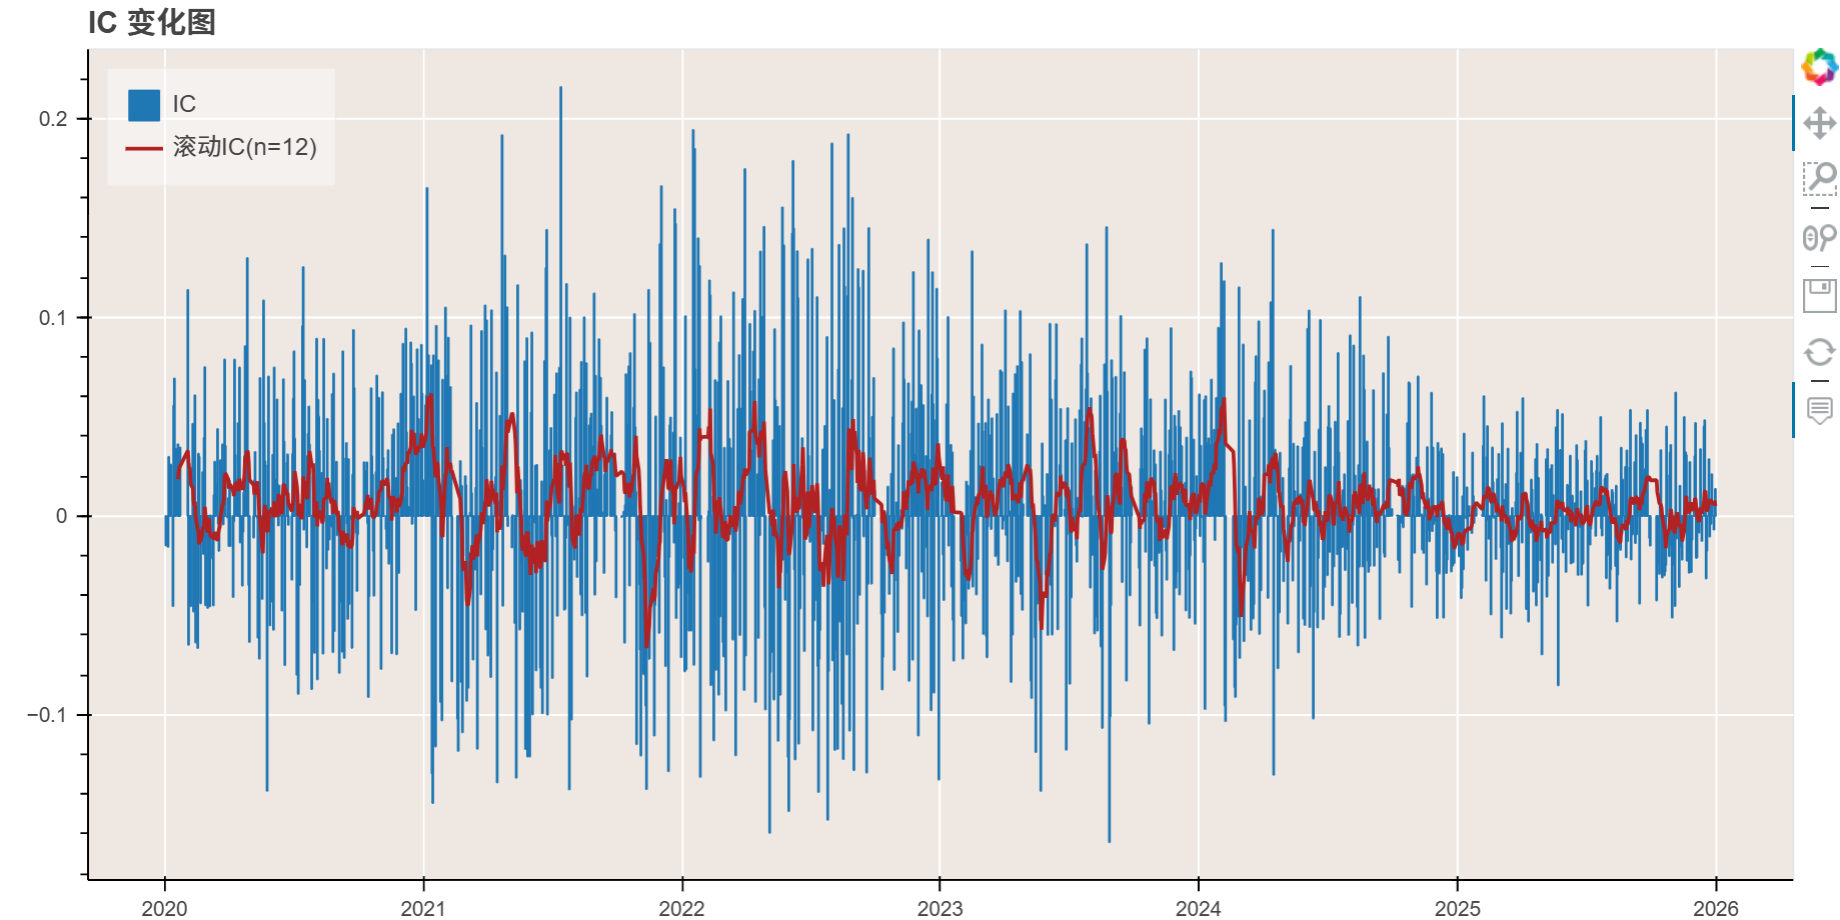

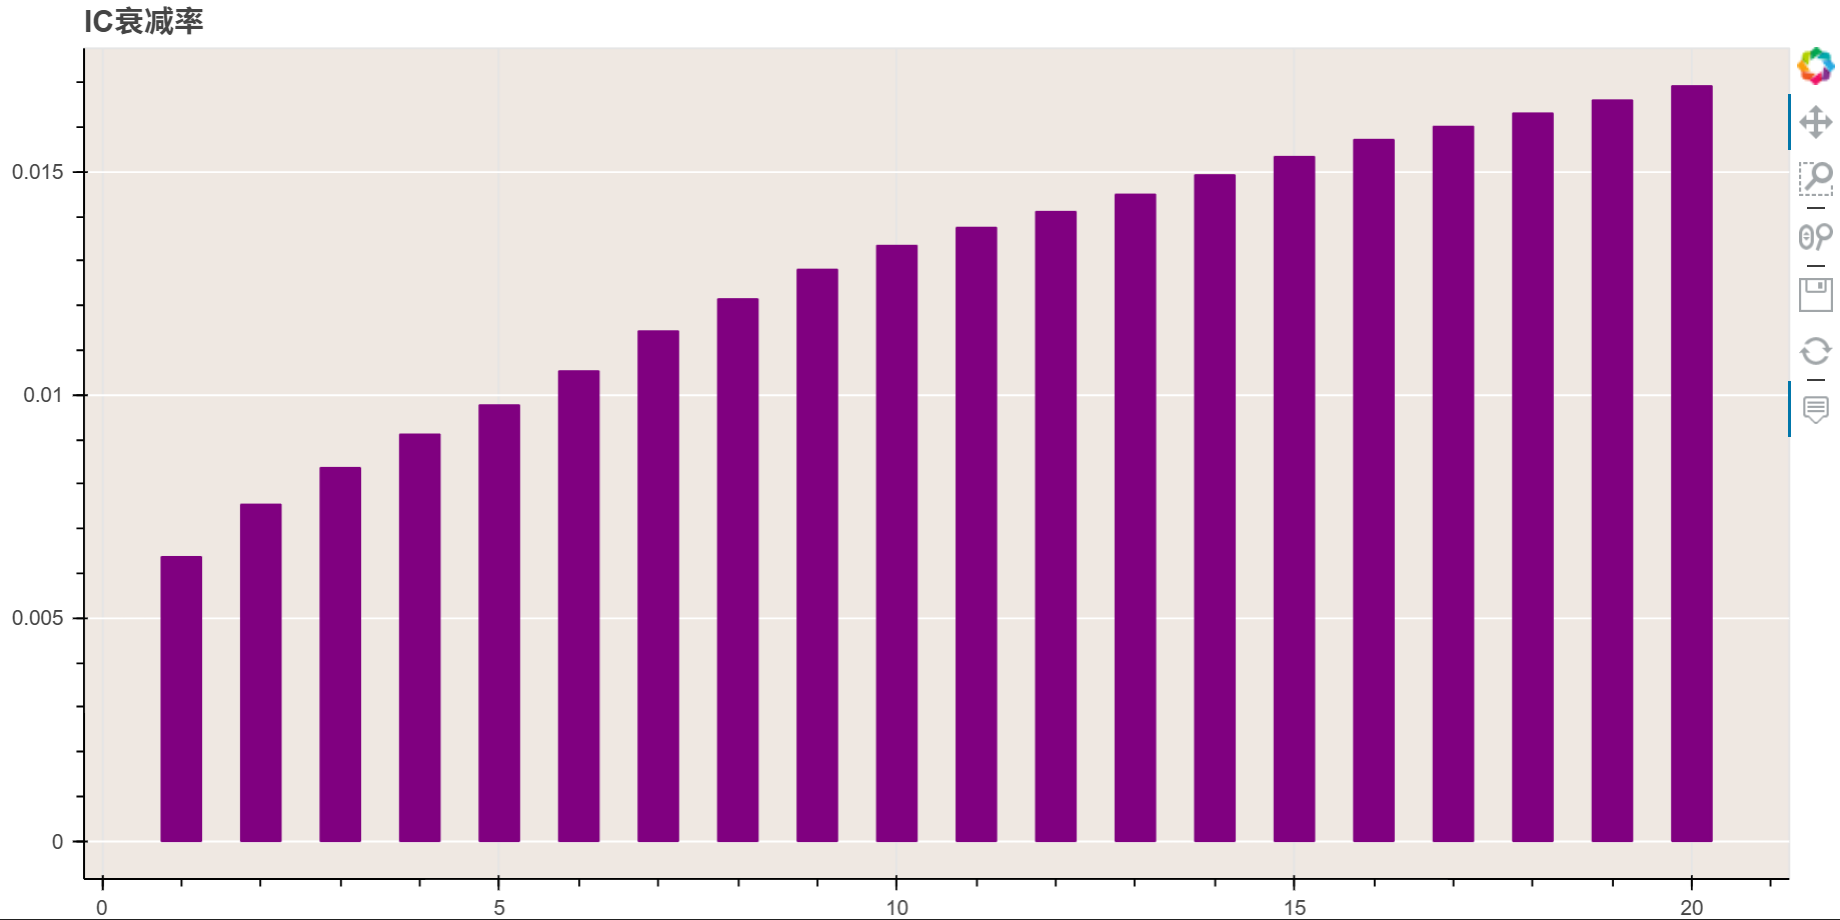

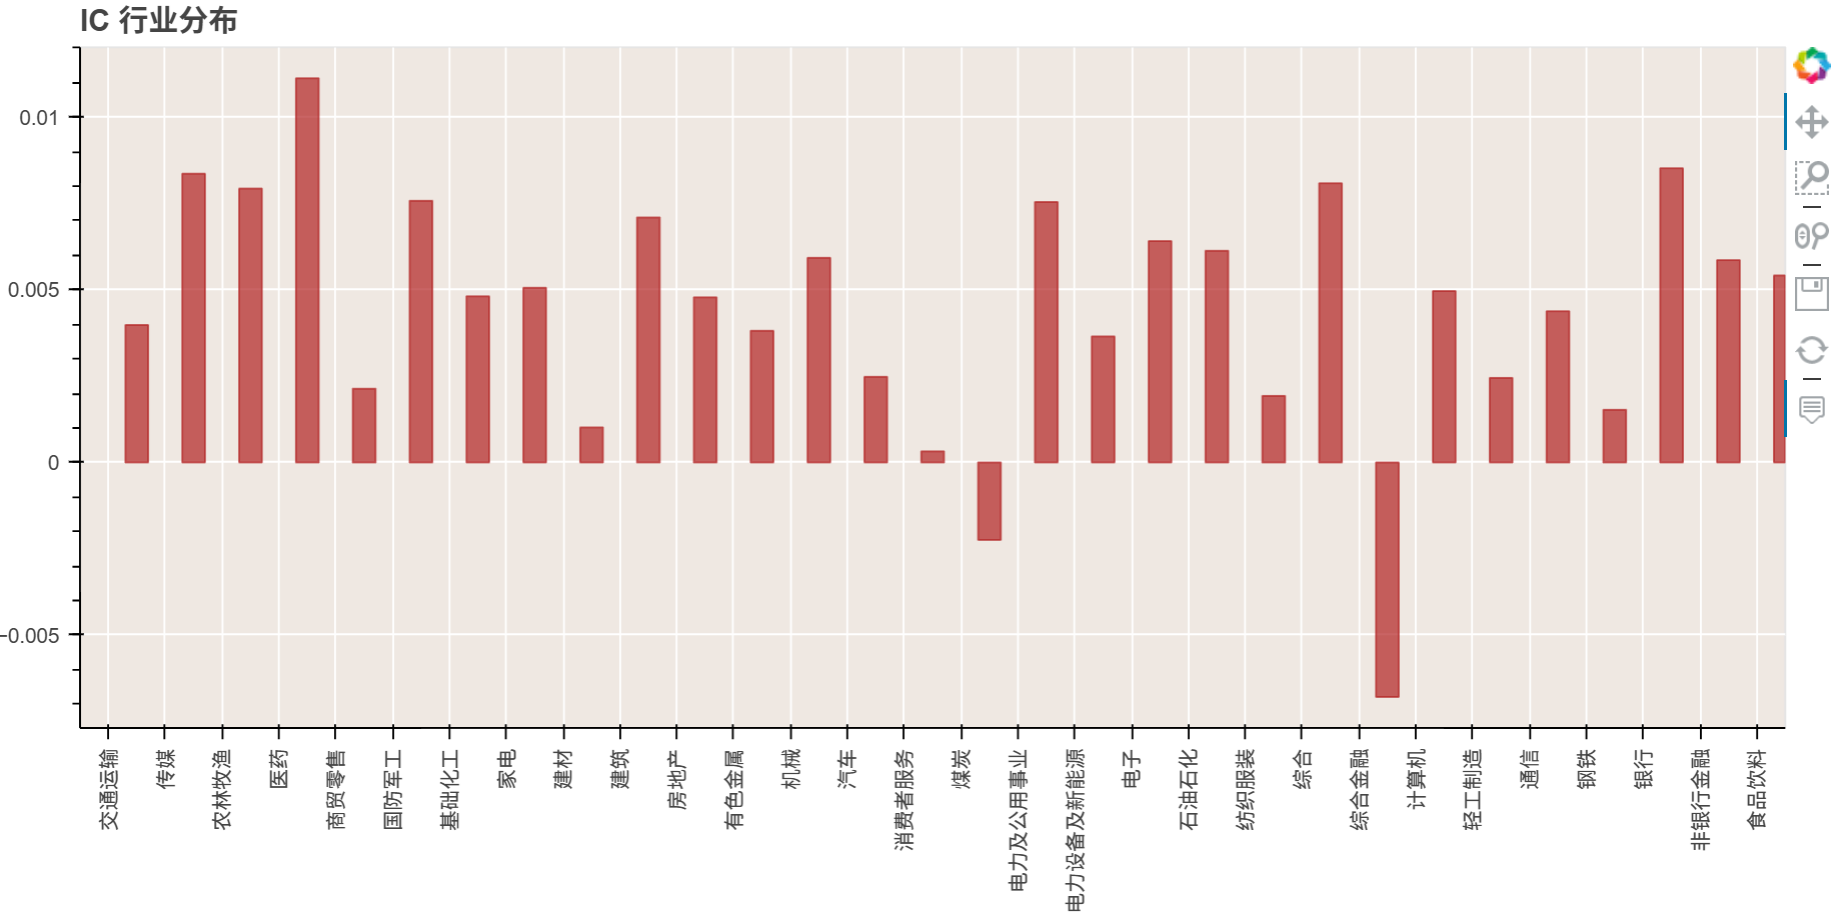

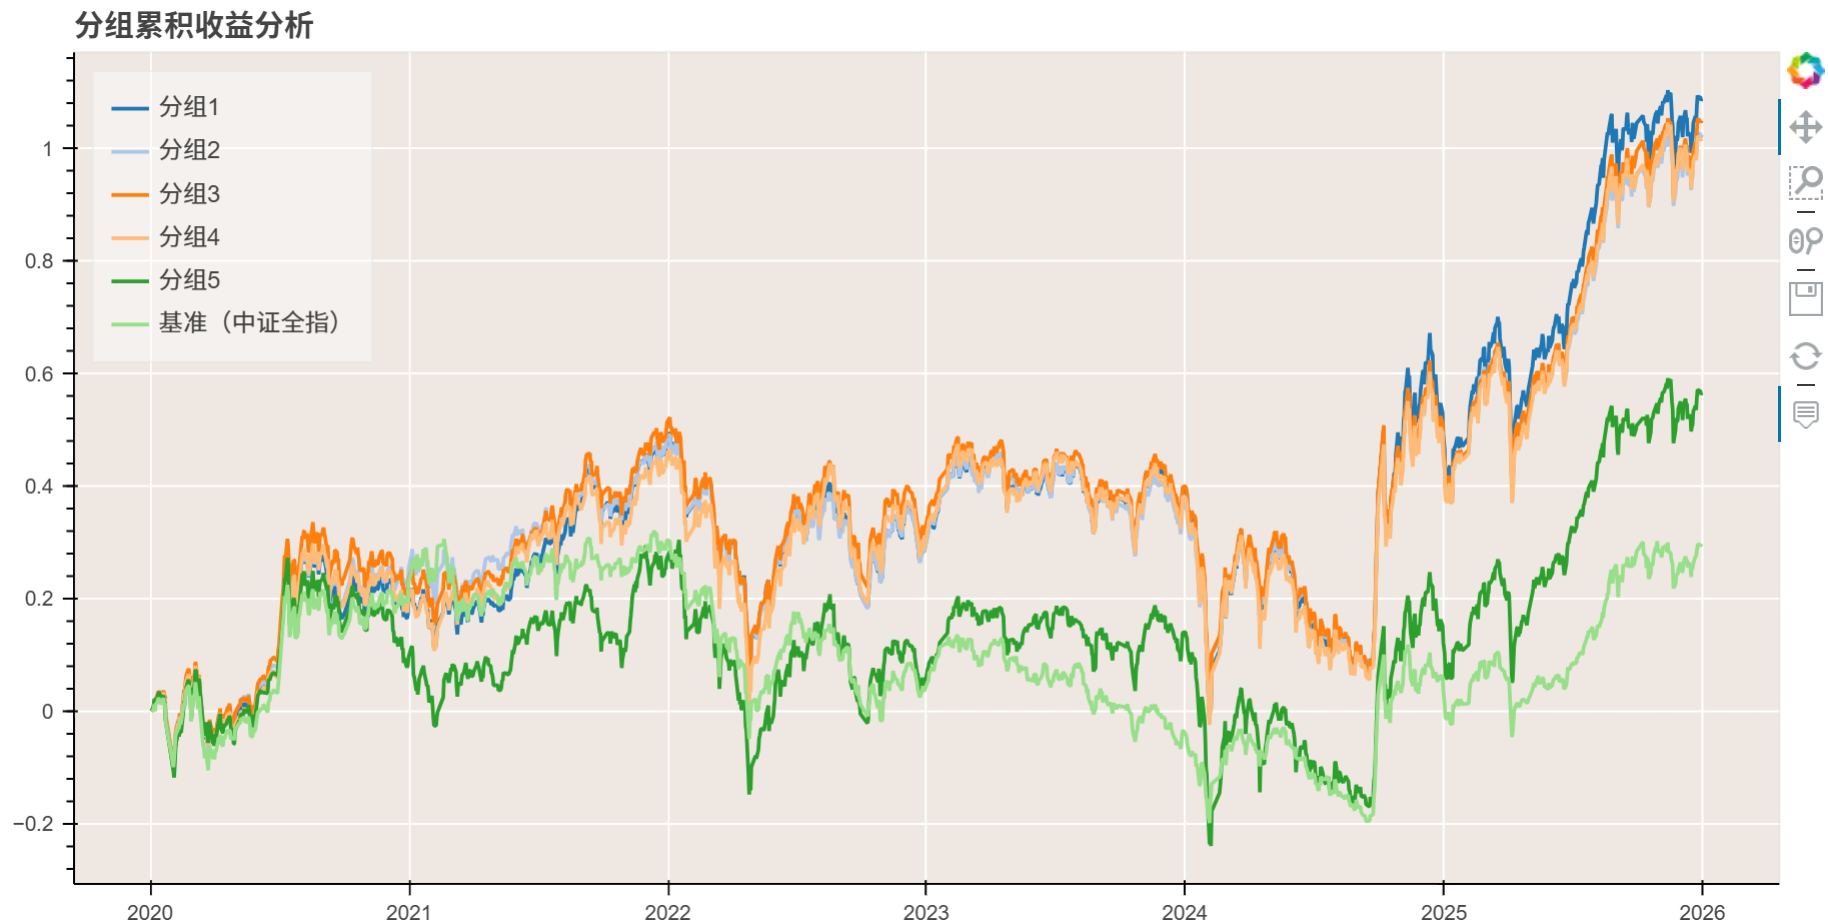

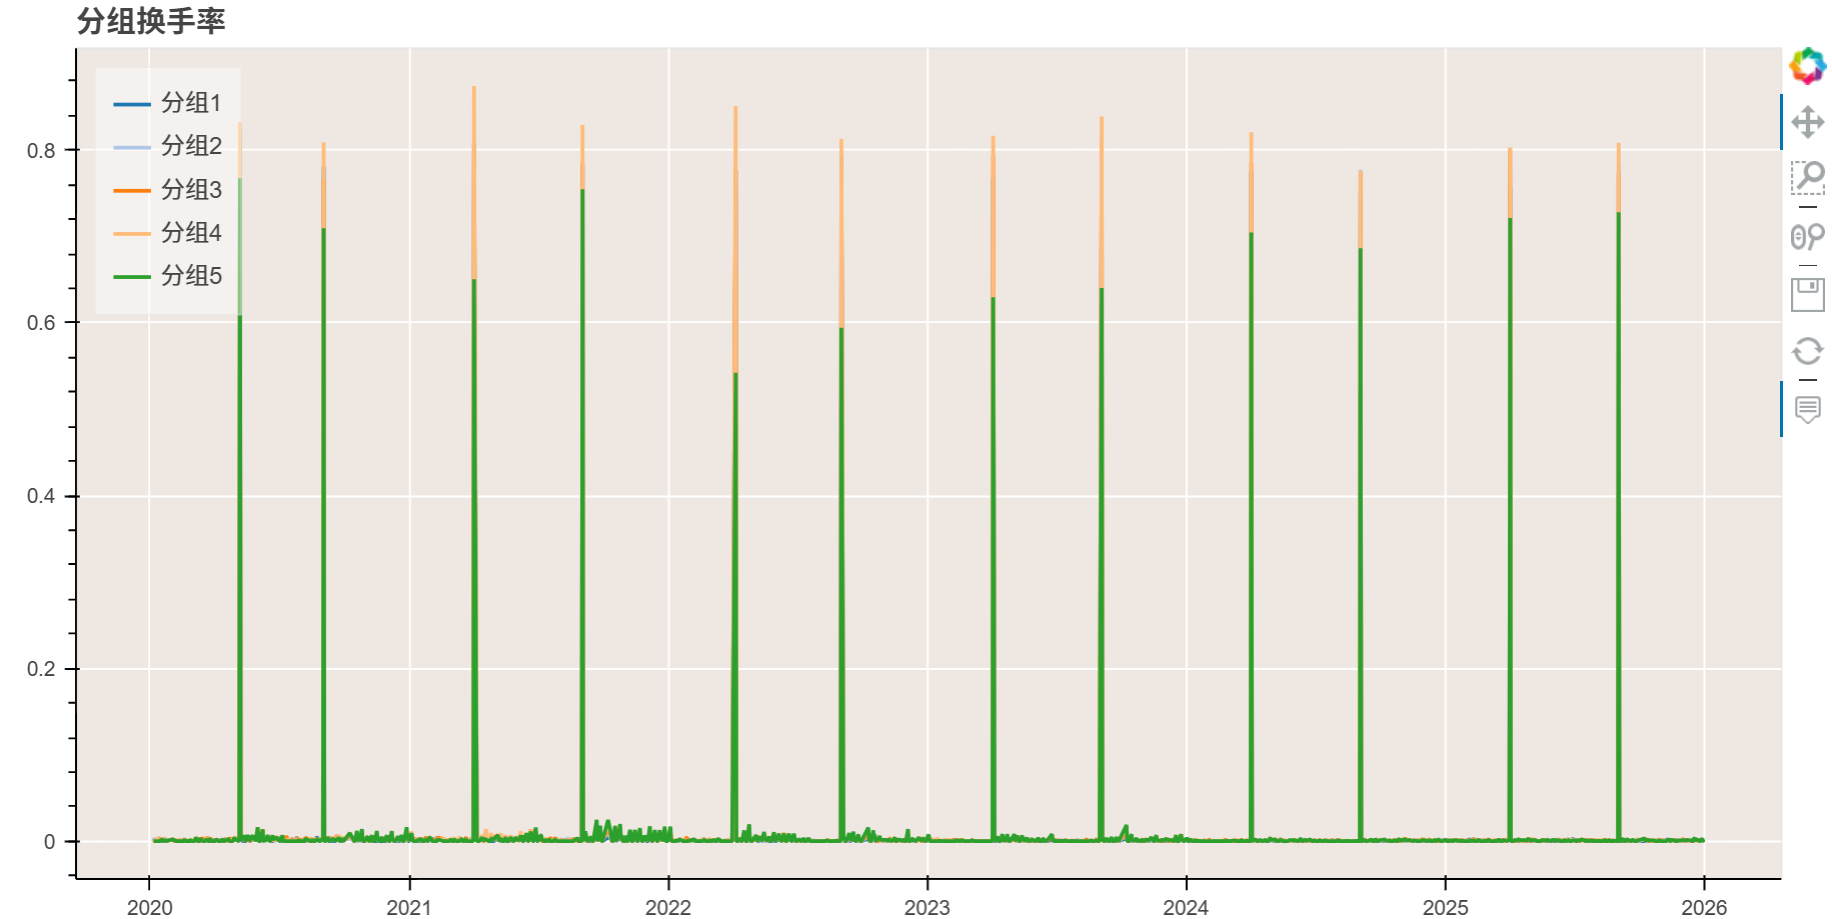

In [ ]:
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

# 替换为你的五年因子测试结果变量
ic = result_raw.ic.dropna()

rolling_window = 12  # 可改为 12，与米筐默认图保持一致
rolling_ic = ic.rolling(rolling_window).mean()
cum_ic = ic.cumsum()

plt.rcParams.update({
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "savefig.facecolor": "white",
    "axes.edgecolor": "#222222",
    "axes.labelcolor": "#222222",
    "xtick.color": "#222222",
    "ytick.color": "#222222",
    "text.color": "#222222",
    "grid.color": "#D0D0D0",
})

fig, ax1 = plt.subplots(figsize=(16, 7))

# 左轴：每日 IC 柱状图 + 滚动 IC
bars = ax1.bar(
    ic.index,
    ic,
    width=0.8,
    color="#4C78A8",
    alpha=0.65,
    label="Daily Rank IC",
)

line_roll, = ax1.plot(
    rolling_ic.index,
    rolling_ic,
    color="#C23B22",
    linewidth=2,
    label=f"{rolling_window}days rolling Rank IC",
)

ax1.axhline(0, color="gray", linewidth=1, linestyle="--")
ax1.set_ylabel("Daily / Rolling Rank IC")
ax1.set_title("Daily IC, Rolling IC and Cumulative Rank IC")

# 右轴：累计 IC
ax2 = ax1.twinx()

line_cum, = ax2.plot(
    cum_ic.index,
    cum_ic,
    color="#2CA02C",
    linewidth=2.2,
    label="Cumulative Rank IC",
)

ax2.set_ylabel("Cumulative Rank IC")

# 横轴日期格式
ax1.xaxis.set_major_locator(mdates.YearLocator())
ax1.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
ax1.grid(axis="y", alpha=0.25)

# 合并双轴图例
ax1.legend(
    [bars, line_roll, line_cum],
    ["Daily Rank IC", f"{rolling_window}days rolling Rank IC", "Cumulative Rank IC"],
    loc="upper left",
)

fig.tight_layout()
plt.show()